# Neural Network Challenge 2026-II · AgroCredit AI
### Predicción de incumplimiento a 12 meses con redes neuronales — Equipo 02

**Contenido**
1. Configuración y carga
2. Auditoría y análisis exploratorio
3. Partición interna
4. Preprocesamiento sin fuga
5. Baseline y experimentos con `MLPClassifier`
6. Red densa con Keras y diagnóstico de ajuste
7. Comparación, selección y evaluación final interna
8. Evaluación e interpretación del modelo final
9. Predicciones para la competencia

**Para ejecutar:** colocar en la misma carpeta `Datos_entrenamiento.csv`, `Competencia_public.csv`, `Competencia_private.csv` y `plantilla_predicciones.csv`, y ejecutar todas las celdas en orden. Tarda unos 30 minutos en CPU. Métrica principal: Average Precision (AP).

## 1. Configuración y carga
Semilla única, versiones registradas y rutas relativas, para que el cuaderno sea reproducible.

In [2]:
import os, sys, time, json, warnings, platform
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
import keras
from keras import layers, regularizers
from pathlib import Path
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, log_loss, precision_recall_curve, roc_curve,
                             confusion_matrix, precision_score, recall_score, f1_score, brier_score_loss)

warnings.filterwarnings("ignore"); tf.get_logger().setLevel("ERROR")
SEMILLA = 20261113                                   # semilla única del proyecto
SEMILLAS = [SEMILLA, SEMILLA + 1, SEMILLA + 2]       # cada experimento se entrena 3 veces
SEMILLAS_ENSAMBLE = [SEMILLA + i for i in range(8)]  # semillas del ensamble final
EQUIPO = "XX"                                        # <-- reemplazar por el número de equipo
np.random.seed(SEMILLA)

pd.set_option("display.max_columns", 80); pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Python", platform.python_version(), "| NumPy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| TensorFlow", tf.__version__, "| Keras", keras.__version__, "| Semilla", SEMILLA)

DATOS = Path(".")                                    # ruta relativa: los CSV están junto al cuaderno
train     = pd.read_csv(DATOS / "Datos_entrenamiento.csv")      # train.csv del enunciado
publico   = pd.read_csv(DATOS / "Competencia_public.csv")       # test_public.csv
privado   = pd.read_csv(DATOS / "Competencia_private.csv")      # test_private.csv
plantilla = pd.read_csv(DATOS / "plantilla_predicciones.csv")
OBJETIVO, ID, COL_PROB = "incumplimiento_12m", "cliente_id", "probabilidad_incumplimiento"
for nombre, df in [("train", train), ("publico", publico), ("privado", privado)]:
    print(f"{nombre:8s} -> {df.shape[0]:>6,} filas x {df.shape[1]} columnas")

Python 3.13.18 | NumPy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1 | TensorFlow 2.21.0 | Keras 3.13.2 | Semilla 20261113
train    -> 21,000 filas x 43 columnas
publico  ->  4,500 filas x 42 columnas
privado  ->  4,500 filas x 42 columnas


**Integridad.** Mismas columnas en los tres archivos, sin IDs repetidos ni clientes compartidos. `cliente_id` se excluye como predictor.

In [3]:
predictoras = [c for c in train.columns if c not in (ID, OBJETIVO)]

assert list(publico.columns) == [ID] + predictoras, "Columnas de publico no coinciden"
assert list(privado.columns) == [ID] + predictoras, "Columnas de privado no coinciden"
assert OBJETIVO not in publico.columns and OBJETIVO not in privado.columns

print("IDs repetidos  train/publico/privado:",
      train[ID].duplicated().sum(), publico[ID].duplicated().sum(), privado[ID].duplicated().sum())
print("Clientes compartidos train-publico  :", len(set(train[ID]) & set(publico[ID])))
print("Clientes compartidos train-privado  :", len(set(train[ID]) & set(privado[ID])))
print("Clientes compartidos publico-privado:", len(set(publico[ID]) & set(privado[ID])))
print("Filas duplicadas completas en train :", train.duplicated().sum())
print("Filas con mismos predictores (sin ID):", train[predictoras].duplicated().sum())
print(f"\nPredictoras disponibles: {len(predictoras)}")

IDs repetidos  train/publico/privado: 0 0 0
Clientes compartidos train-publico  : 0
Clientes compartidos train-privado  : 0
Clientes compartidos publico-privado: 0
Filas duplicadas completas en train : 0
Filas con mismos predictores (sin ID): 0

Predictoras disponibles: 41


## 2. Auditoría y análisis exploratorio
Aquí solo se describe; no se ajusta ningún parámetro. Cada hallazgo es una hipótesis de preprocesamiento que se contrasta en la sección 4.

### 2.1 Tipos de variables y objetivo

In [4]:
categoricas = train[predictoras].select_dtypes(exclude="number").columns.tolist()
numericas   = [c for c in predictoras if c not in categoricas]
enteras     = [c for c in numericas if (train[c].dropna() % 1 == 0).all()]
continuas   = [c for c in numericas if c not in enteras]

print(f"Categóricas ({len(categoricas)}):", categoricas)
print(f"\nEnteras / conteos ({len(enteras)}):", enteras)
print(f"\nContinuas ({len(continuas)}):", continuas)

Categóricas (9): ['region', 'cultivo_principal', 'tipo_cliente', 'garantia', 'canal_solicitud', 'seguro_agricola', 'nivel_educativo', 'tipo_riego', 'formalizado']

Enteras / conteos (10): ['edad', 'plazo_meses', 'score_crediticio', 'retrasos_12m', 'creditos_activos', 'consultas_crediticias_6m', 'dias_mora_historica', 'antiguedad_banco_meses', 'numero_dependientes', 'transacciones_mensuales']

Continuas (22): ['antiguedad_negocio_anios', 'ingreso_mensual', 'deuda_total', 'monto_credito', 'tasa_interes', 'saldo_promedio', 'ventas_anuales', 'hectareas_cultivadas', 'rendimiento_ton_ha', 'variabilidad_ingresos', 'perdidas_cosecha_pct', 'dependencia_cliente_principal', 'ratio_deuda_ingreso', 'ratio_cuota_ingreso', 'uso_banca_digital_pct', 'indice_estacionalidad', 'temperatura_promedio', 'precipitacion_mm', 'indice_riesgo_climatico', 'distancia_mercado_km', 'variable_ruido_1', 'variable_ruido_2']


incumplimiento_12m
No incumple (0)    17209
Incumple (1)        3791

Prevalencia de incumplimiento: 0.1805 (18.05%)
Razón de desbalance: 1 incumplidor por cada 4.5 cumplidores


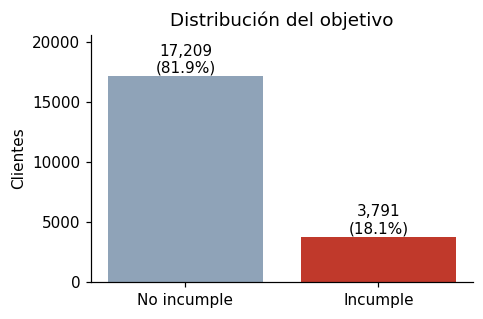

In [5]:
conteo = train[OBJETIVO].value_counts().sort_index()
prevalencia = train[OBJETIVO].mean()
print(conteo.rename({0: "No incumple (0)", 1: "Incumple (1)"}).to_string())
print(f"\nPrevalencia de incumplimiento: {prevalencia:.4f} ({prevalencia:.2%})")
print(f"Razón de desbalance: 1 incumplidor por cada {(1-prevalencia)/prevalencia:.1f} cumplidores")

fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(["No incumple", "Incumple"], conteo.values, color=["#8fa3b8", "#c0392b"])
for i, v in enumerate(conteo.values):
    ax.text(i, v, f"{v:,}\n({v/len(train):.1%})", ha="center", va="bottom")
ax.set_ylim(0, conteo.max() * 1.2); ax.set_ylabel("Clientes"); ax.set_title("Distribución del objetivo")
plt.tight_layout(); plt.show()

Desbalance moderado: **18 % de positivos**. Un modelo aleatorio tendría AP ≈ 0,18 (la referencia mínima). La partición deberá ser estratificada.

### 2.2 Valores faltantes

In [6]:
faltantes = pd.DataFrame({
    "tipo": ["categórica" if c in categoricas else "numérica" for c in predictoras],
    "train_%":   train[predictoras].isna().mean() * 100,
    "publico_%": publico[predictoras].isna().mean() * 100,
    "privado_%": privado[predictoras].isna().mean() * 100,
})
faltantes = faltantes[faltantes["train_%"] > 0].sort_values("train_%", ascending=False)
con_faltantes = faltantes.index.tolist()
display(faltantes)

por_fila = train[predictoras].isna().sum(axis=1).value_counts().sort_index()
print("Número de faltantes por fila (train):")
print((por_fila / len(train) * 100).round(1).astype(str).add(" %").to_string())

,tipo,train_%,publico_%,privado_%
score_crediticio,numérica,9.5619,9.9778,10.6444
precipitacion_mm,numérica,8.2905,8.3111,8.9778
ingreso_mensual,numérica,7.6333,7.4667,7.5333
garantia,categórica,7.5190,7.3333,8.0889
rendimiento_ton_ha,numérica,6.9381,7.0444,6.7333
saldo_promedio,numérica,6.9286,7.4444,6.8889
tipo_riego,categórica,4.2238,4.2889,4.2444
nivel_educativo,categórica,3.7333,4.0444,4.1111


Número de faltantes por fila (train):
0    56.3 %
1    34.0 %
2     8.3 %
3     1.3 %
4     0.1 %
5     0.0 %


In [7]:
# ¿La ausencia del dato se asocia con el incumplimiento?
filas = []
for c in con_faltantes:
    falta = train[c].isna()
    filas.append({"variable": c,
                  "tasa_incumpl_si_falta": train.loc[falta, OBJETIVO].mean(),
                  "tasa_incumpl_si_presente": train.loc[~falta, OBJETIVO].mean()})
asoc = pd.DataFrame(filas).set_index("variable")
asoc["diferencia_pp"] = (asoc["tasa_incumpl_si_falta"] - asoc["tasa_incumpl_si_presente"]) * 100
display(asoc.sort_values("diferencia_pp", ascending=False))

# ¿Los faltantes aparecen juntos? (correlación entre indicadores de ausencia)
ind = train[con_faltantes].isna().astype(int).corr().abs()
print("Máxima correlación entre indicadores de ausencia:",
      round(ind.where(~np.eye(len(ind), dtype=bool)).max().max(), 3))

,tasa_incumpl_si_falta,tasa_incumpl_si_presente,diferencia_pp
variable,,,
ingreso_mensual,0.1946,0.1794,1.5277
score_crediticio,0.1942,0.1791,1.5148
nivel_educativo,0.1939,0.1800,1.3872
saldo_promedio,0.1931,0.1796,1.3542
rendimiento_ton_ha,0.1860,0.1801,0.5883
precipitacion_mm,0.1706,0.1814,-1.0830
tipo_riego,0.1691,0.1810,-1.1918
garantia,0.1672,0.1816,-1.4413


Máxima correlación entre indicadores de ausencia: 0.014


8 variables con 4–10 % de faltantes y 44 % de filas con alguno: se imputa, no se eliminan filas. La ausencia no muestra una relación clara con el objetivo.

### 2.3 Distribuciones y asimetría

In [8]:
resumen = train[numericas].describe(percentiles=[.01, .5, .99]).T[["min", "1%", "50%", "99%", "max"]]
resumen["asimetria"] = train[numericas].skew()
resumen["negativos"] = (train[numericas] < 0).sum()
display(resumen.sort_values("asimetria", ascending=False))

,min,1%,50%,99%,max,asimetria,negativos
ratio_cuota_ingreso,0.0010,0.0080,0.1140,1.7600,11.3940,7.1291,0
saldo_promedio,29.8900,142.6832,"1,841.4900","22,614.7136","131,494.9100",6.5750,0
ratio_deuda_ingreso,0.0010,0.0080,0.1150,1.5031,9.0100,5.7926,0
deuda_total,127.7700,747.2697,"6,085.8800","48,231.5380","194,594.8800",4.3442,0
hectareas_cultivadas,0.0800,0.6500,5.5350,45.0703,160.5300,3.9944,0
ventas_anuales,"1,405.8500","6,354.2117","44,768.0450","320,187.3900","1,178,207.5800",3.6802,0
ingreso_mensual,303.1600,920.1584,"4,425.8600","21,747.7616","81,972.6400",2.8890,0
monto_credito,586.2600,"2,171.5435","9,862.6000","44,596.1164","150,103.9500",2.4690,0
distancia_mercado_km,0.1000,3.0000,33.9000,129.8000,260.5000,1.3849,0
precipitacion_mm,1.1000,7.3000,83.8000,331.1100,548.5000,1.3679,0


Variables con asimetría > 2 y sin negativos (candidatas a log1p):
['ingreso_mensual', 'deuda_total', 'monto_credito', 'saldo_promedio', 'ventas_anuales', 'hectareas_cultivadas', 'ratio_deuda_ingreso', 'ratio_cuota_ingreso']


,minimo,asimetria_original,asimetria_log1p,asimetria_log
ingreso_mensual,303.1600,2.8890,0.0062,0.0056
deuda_total,127.7700,4.3442,-0.0183,-0.0190
monto_credito,586.2600,2.4690,-0.0174,-0.0177
saldo_promedio,29.8900,6.5750,-0.0160,-0.0191
ventas_anuales,"1,405.8500",3.6802,0.0083,0.0082
hectareas_cultivadas,0.0800,3.9944,0.3963,-0.0328
ratio_deuda_ingreso,0.0010,5.7926,2.7060,-0.0281
ratio_cuota_ingreso,0.0010,7.1291,2.8056,0.0745


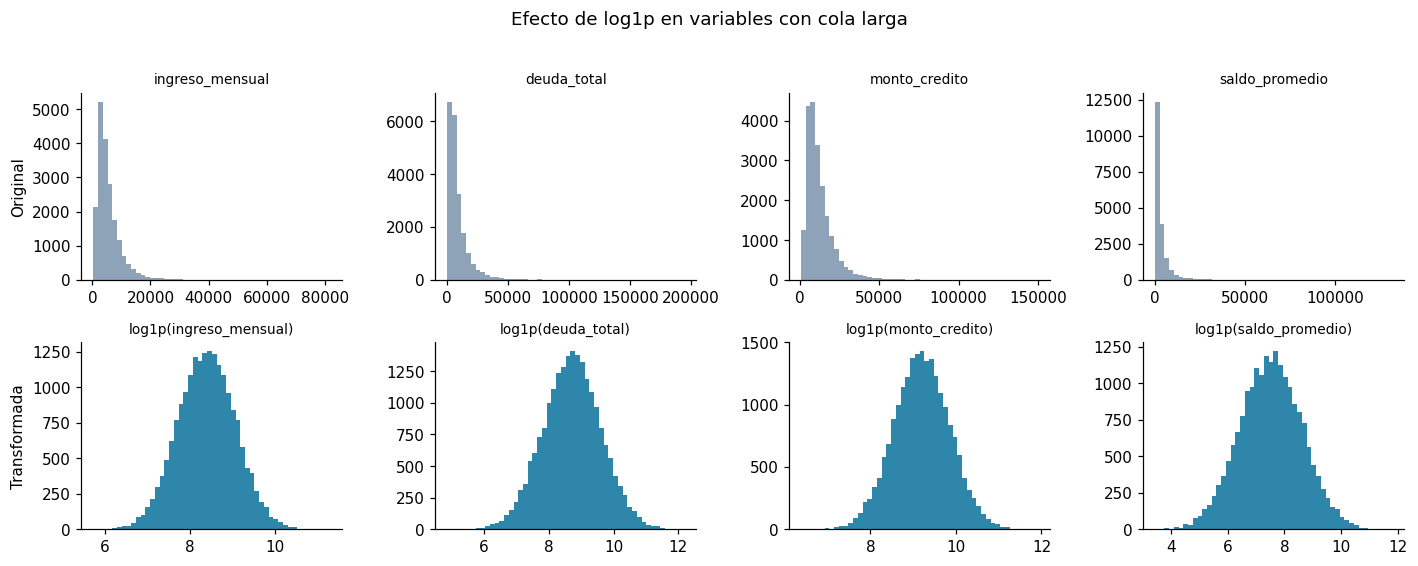

In [9]:
asimetricas = resumen.index[(resumen["asimetria"] > 2) & (resumen["min"] >= 0)].tolist()
print("Variables con asimetría > 2 y sin negativos (candidatas a log1p):")
print(asimetricas)

comparacion = pd.DataFrame({"minimo": train[asimetricas].min(),
                            "asimetria_original": train[asimetricas].skew(),
                            "asimetria_log1p": np.log1p(train[asimetricas]).skew(),
                            "asimetria_log": np.log(train[asimetricas]).skew()})
display(comparacion)

fig, axes = plt.subplots(2, 4, figsize=(13, 5))
for j, c in enumerate(asimetricas[:4]):
    axes[0, j].hist(train[c].dropna(), bins=50, color="#8fa3b8"); axes[0, j].set_title(c, fontsize=9)
    axes[1, j].hist(np.log1p(train[c].dropna()), bins=50, color="#2e86ab"); axes[1, j].set_title(f"log1p({c})", fontsize=9)
axes[0, 0].set_ylabel("Original"); axes[1, 0].set_ylabel("Transformada")
plt.suptitle("Efecto de log1p en variables con cola larga", y=1.02); plt.tight_layout(); plt.show()

8 variables con cola derecha larga. El logaritmo las vuelve simétricas; si eso mejora el modelo se comprueba en la sección 4. No se eliminan valores extremos.

### 2.4 Consistencia y variables derivadas

In [10]:
controles = {
    "edad fuera de [18, 100]":                  ((train["edad"] < 18) | (train["edad"] > 100)).mean(),
    "score fuera de [300, 850]":                ((train["score_crediticio"] < 300) | (train["score_crediticio"] > 850)).mean(),
    "proporciones fuera de [0, 1]":             ((train[["perdidas_cosecha_pct", "uso_banca_digital_pct", "dependencia_cliente_principal"]] < 0)
                                                 | (train[["perdidas_cosecha_pct", "uso_banca_digital_pct", "dependencia_cliente_principal"]] > 1)).any(axis=1).mean(),
    "montos <= 0":                              (train[["ingreso_mensual", "deuda_total", "monto_credito", "ventas_anuales"]] <= 0).any(axis=1).mean(),
    "negocio más antiguo que (edad - 15)":      (train["antiguedad_negocio_anios"] > train["edad"] - 15).mean(),
    "banco más antiguo que (edad - 18)":        (train["antiguedad_banco_meses"] / 12 > train["edad"] - 18).mean(),
    "ratio_cuota_ingreso > 1":                  (train["ratio_cuota_ingreso"] > 1).mean(),
    "ratio_deuda_ingreso > 1":                  (train["ratio_deuda_ingreso"] > 1).mean(),
}
display(pd.Series(controles, name="% de filas").mul(100).round(2).to_frame())

,% de filas
"edad fuera de [18, 100]",0.0000
"score fuera de [300, 850]",0.0000
"proporciones fuera de [0, 1]",0.0000
montos <= 0,0.0000
negocio más antiguo que (edad - 15),11.3200
banco más antiguo que (edad - 18),12.9500
ratio_cuota_ingreso > 1,3.4700
ratio_deuda_ingreso > 1,2.6400


In [11]:
# ¿Los ratios son fórmulas de otras columnas?
ok = train["ingreso_mensual"].notna()
rdi_calc = train["deuda_total"] / (12 * train["ingreso_mensual"])          # deuda / ingreso anual
rci_calc = (train["monto_credito"] / train["plazo_meses"]) / train["ingreso_mensual"]   # cuota simple / ingreso mensual

print("ratio_deuda_ingreso vs deuda/(12*ingreso)   -> error absoluto máximo:",
      round((rdi_calc - train["ratio_deuda_ingreso"])[ok].abs().max(), 5))
print("ratio_cuota_ingreso vs (monto/plazo)/ingreso -> correlación:",
      round(np.corrcoef(rci_calc[ok], train.loc[ok, "ratio_cuota_ingreso"])[0, 1], 5))

# Los ratios existen incluso cuando falta el ingreso
sin_ingreso = train["ingreso_mensual"].isna()
print(f"\nFilas sin ingreso_mensual: {sin_ingreso.sum():,}")
print("  ...con ratio_deuda_ingreso disponible:", train.loc[sin_ingreso, "ratio_deuda_ingreso"].notna().mean())

# Precisión de reconstruir el ingreso a partir del ratio (medida donde sí se conoce el ingreso)
ingreso_rec = train["deuda_total"] / (12 * train["ratio_deuda_ingreso"])
err = (ingreso_rec[ok] / train.loc[ok, "ingreso_mensual"] - 1).abs()
print("\nError relativo al reconstruir ingreso = deuda / (12 * ratio_deuda_ingreso):")
print(err.describe(percentiles=[.5, .9, .99])[["50%", "90%", "99%", "max"]].round(4).to_string())
print("Error relativo de imputar con la mediana:",
      round((train["ingreso_mensual"].median() / train.loc[ok, "ingreso_mensual"] - 1).abs().median(), 3), "(mediana)")

ratio_deuda_ingreso vs deuda/(12*ingreso)   -> error absoluto máximo: 0.0005
ratio_cuota_ingreso vs (monto/plazo)/ingreso -> correlación: 1.0

Filas sin ingreso_mensual: 1,603
  ...con ratio_deuda_ingreso disponible: 1.0

Error relativo al reconstruir ingreso = deuda / (12 * ratio_deuda_ingreso):
50%   0.0018
90%   0.0097
99%   0.0359
max   0.2464
Error relativo de imputar con la mediana: 0.436 (mediana)


`ratio_deuda_ingreso` = `deuda_total / (12 × ingreso_mensual)` y existe aunque el ingreso falte: permite **reconstruir el ingreso faltante** con un error típico de 0,2 % (fórmula fija, sin fuga).

### 2.5 Variables categóricas

In [12]:
filas = []
for c in categoricas:
    frec = train[c].value_counts(normalize=True)
    filas.append({"variable": c, "n_categorias": frec.size,
                  "categoria_menos_frecuente": frec.index[-1], "frecuencia_min_%": frec.iloc[-1] * 100,
                  "nuevas_en_publico": len(set(publico[c].dropna()) - set(train[c].dropna())),
                  "nuevas_en_privado": len(set(privado[c].dropna()) - set(train[c].dropna()))})
display(pd.DataFrame(filas).set_index("variable"))

,n_categorias,categoria_menos_frecuente,frecuencia_min_%,nuevas_en_publico,nuevas_en_privado
variable,,,,,
region,3,Selva,19.1190,0,0
cultivo_principal,7,Cacao,14.0476,0,0
tipo_cliente,3,Pequena empresa,14.7952,0,0
garantia,4,Aval,18.2019,0,0
canal_solicitud,4,Web,24.6571,0,0
seguro_agricola,2,Si,42.6667,0,0
nivel_educativo,4,Universitario,14.2115,0,0
tipo_riego,3,Tecnificado,27.0522,0,0
formalizado,2,No,41.5952,0,0


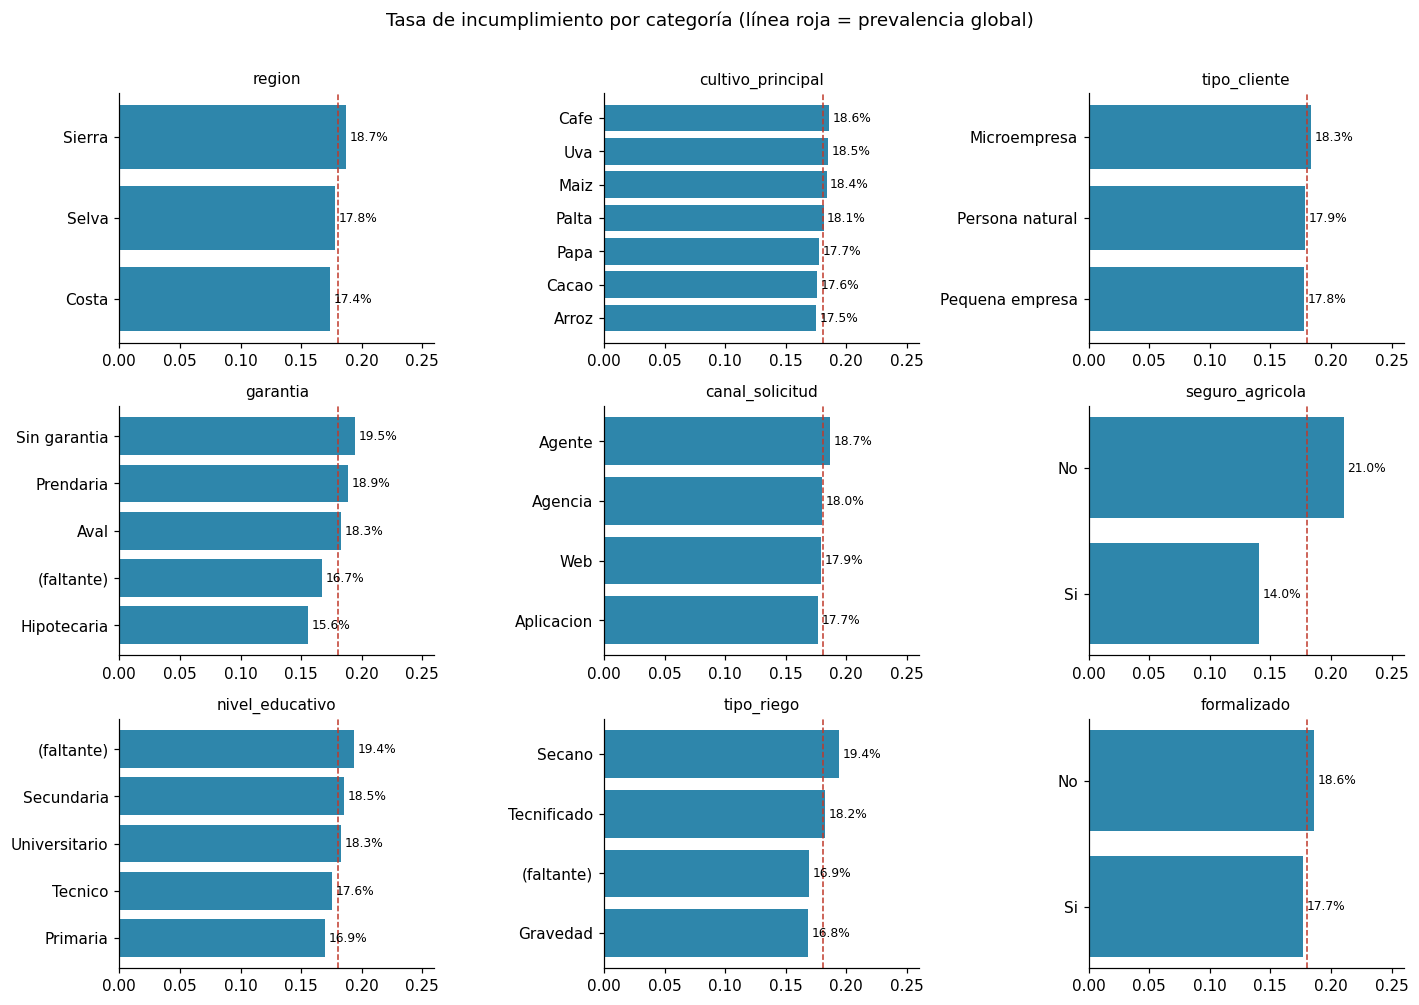

In [13]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, c in zip(axes.ravel(), categoricas):
    tasa = train.fillna({c: "(faltante)"}).groupby(c)[OBJETIVO].mean().sort_values()
    ax.barh(tasa.index, tasa.values, color="#2e86ab")
    ax.axvline(prevalencia, color="#c0392b", ls="--", lw=1)
    ax.set_title(c, fontsize=10); ax.set_xlim(0, 0.26)
    for i, v in enumerate(tasa.values): ax.text(v + 0.003, i, f"{v:.1%}", va="center", fontsize=8)
plt.suptitle("Tasa de incumplimiento por categoría (línea roja = prevalencia global)", y=1.01)
plt.tight_layout(); plt.show()

Entre 2 y 7 categorías, ninguna rara ni nueva en los archivos de competencia: one-hot directo.

### 2.6 Relación con el objetivo y redundancia

,auc_univariado,poder,sentido
variable,,,
score_crediticio,0.3268,0.1732,más valor = menos riesgo
ratio_cuota_ingreso,0.5781,0.0781,más valor = más riesgo
ingreso_mensual,0.4357,0.0643,más valor = menos riesgo
antiguedad_negocio_anios,0.4418,0.0582,más valor = menos riesgo
ratio_deuda_ingreso,0.5561,0.0561,más valor = más riesgo
indice_riesgo_climatico,0.5442,0.0442,más valor = más riesgo
retrasos_12m,0.5411,0.0411,más valor = más riesgo
monto_credito,0.5392,0.0392,más valor = más riesgo
plazo_meses,0.4610,0.0390,más valor = menos riesgo


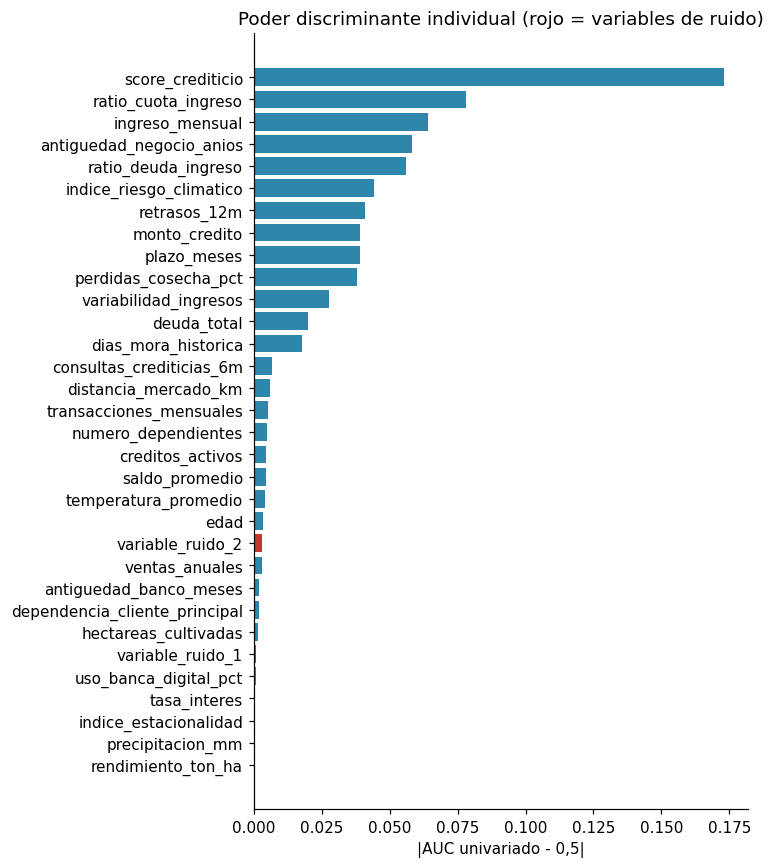

In [14]:
filas = []
for c in numericas:
    m = train[c].notna()
    auc = roc_auc_score(train.loc[m, OBJETIVO], train.loc[m, c])
    filas.append({"variable": c, "auc_univariado": auc, "poder": abs(auc - 0.5),
                  "sentido": "más valor = más riesgo" if auc > 0.5 else "más valor = menos riesgo"})
poder = pd.DataFrame(filas).set_index("variable").sort_values("poder", ascending=False)
display(poder.head(14))

fig, ax = plt.subplots(figsize=(7, 8))
p = poder.sort_values("poder")
colores = ["#c0392b" if "ruido" in v else "#2e86ab" for v in p.index]
ax.barh(p.index, p["poder"], color=colores)
ax.set_xlabel("|AUC univariado - 0,5|"); ax.set_title("Poder discriminante individual (rojo = variables de ruido)")
plt.tight_layout(); plt.show()

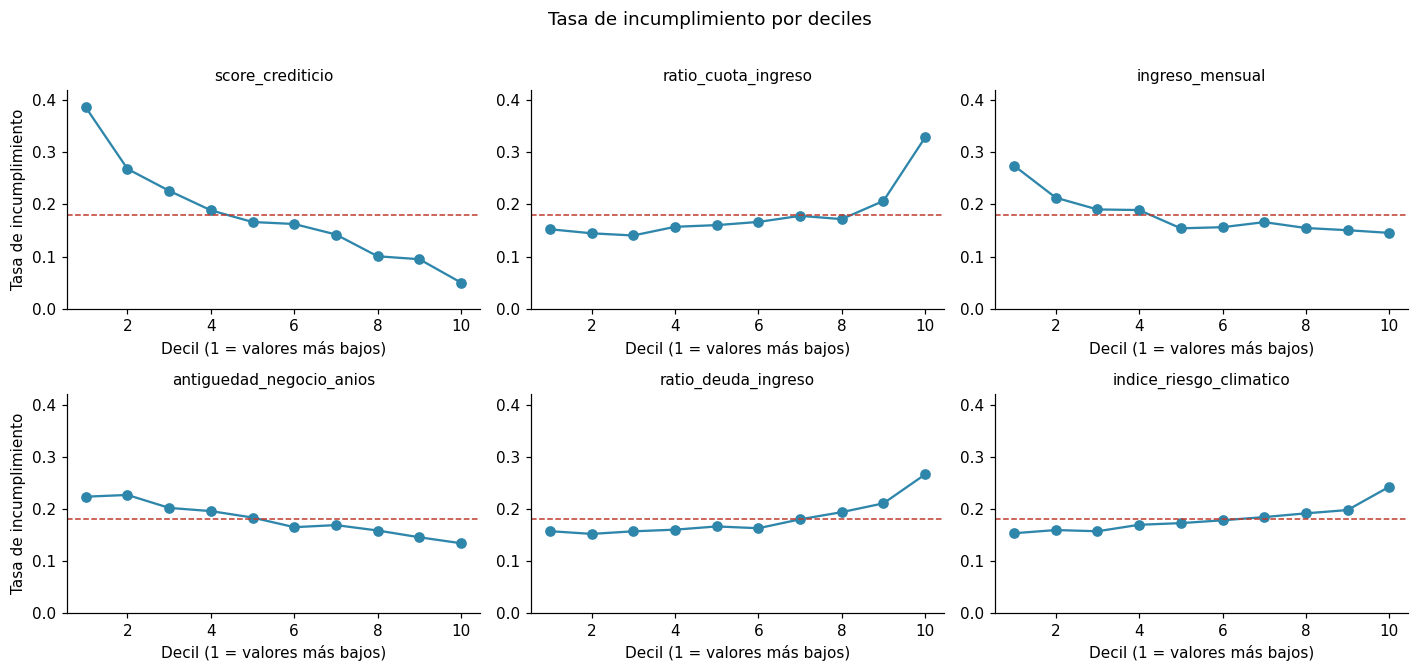

,tasa,clientes
retrasos_12m,,
0,0.1625,9466
1,0.1766,7612
2,0.2209,2924
3,0.2683,805
4,0.2395,167
5,0.2692,26


In [15]:
# Forma de la relación para las variables con más señal: tasa de incumplimiento por deciles
principales = ["score_crediticio", "ratio_cuota_ingreso", "ingreso_mensual", "antiguedad_negocio_anios",
               "ratio_deuda_ingreso", "indice_riesgo_climatico"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, c in zip(axes.ravel(), principales):
    grupos = pd.qcut(train[c], 10, duplicates="drop")
    tasa = train.groupby(grupos, observed=True)[OBJETIVO].mean()
    ax.plot(range(1, len(tasa) + 1), tasa.values, marker="o", color="#2e86ab")
    ax.axhline(prevalencia, color="#c0392b", ls="--", lw=1)
    ax.set_title(c, fontsize=10); ax.set_xlabel("Decil (1 = valores más bajos)"); ax.set_ylim(0, 0.42)
axes[0, 0].set_ylabel("Tasa de incumplimiento"); axes[1, 0].set_ylabel("Tasa de incumplimiento")
plt.suptitle("Tasa de incumplimiento por deciles", y=1.01); plt.tight_layout(); plt.show()

display(train.groupby("retrasos_12m")[OBJETIVO].agg(tasa="mean", clientes="size"))

In [16]:
corr = train[numericas].corr(method="spearman")
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()
             .rename("spearman").reset_index().rename(columns={"level_0": "variable_1", "level_1": "variable_2"}))
pares["abs"] = pares["spearman"].abs()
display(pares.sort_values("abs", ascending=False).head(8).drop(columns="abs"))
print("Pares con |correlación| > 0,10:", (pares["abs"] > 0.10).sum(), "de", len(pares))

,variable_1,variable_2,spearman
105,deuda_total,ratio_deuda_ingreso,0.7809
77,ingreso_mensual,ratio_deuda_ingreso,-0.5852
159,plazo_meses,ratio_cuota_ingreso,-0.5852
78,ingreso_mensual,ratio_cuota_ingreso,-0.5577
133,monto_credito,ratio_cuota_ingreso,0.5394
418,ratio_deuda_ingreso,ratio_cuota_ingreso,0.3406
64,ingreso_mensual,tasa_interes,0.0203
292,saldo_promedio,dias_mora_historica,0.0203


Pares con |correlación| > 0,10: 6 de 496


**Hallazgos del EDA**
- La señal está concentrada en `score_crediticio` (el decil más bajo incumple 39 %; el más alto, 5 %) y `ratio_cuota_ingreso` (salto no lineal en el último decil).
- Las dos variables de ruido no aportan; el resto de predictoras son casi independientes entre sí.

## 3. Partición interna
División estratificada 70 / 15 / 15: **entrenamiento** (ajustar), **validación** (comparar y elegir) y **final interno** (una sola evaluación, al final).

In [17]:
# Listas de trabajo definidas a partir del EDA
VARIABLES_LOG1P   = ["ingreso_mensual", "deuda_total", "monto_credito", "saldo_promedio", "ventas_anuales", "hectareas_cultivadas"]
VARIABLES_LOG     = ["ratio_deuda_ingreso", "ratio_cuota_ingreso"]
VARIABLES_RUIDO   = ["variable_ruido_1", "variable_ruido_2"]
NUM_CON_FALTANTES = ["score_crediticio", "precipitacion_mm", "ingreso_mensual", "rendimiento_ton_ha", "saldo_promedio"]

In [18]:
X, y = train[predictoras], train[OBJETIVO]

# Paso 1: se aparta el 15 % final interno
X_desarrollo, X_final, y_desarrollo, y_final = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=SEMILLA)

# Paso 2: el 85 % restante se divide en entrenamiento (70 % del total) y validación (15 % del total)
X_train, X_val, y_train, y_val = train_test_split(
    X_desarrollo, y_desarrollo, test_size=0.15 / 0.85, stratify=y_desarrollo, random_state=SEMILLA)

particion = pd.DataFrame({
    "filas": [len(X_train), len(X_val), len(X_final)],
    "positivos": [y_train.sum(), y_val.sum(), y_final.sum()],
    "prevalencia": [y_train.mean(), y_val.mean(), y_final.mean()],
}, index=["entrenamiento", "validación", "final interno"])
particion["% del total"] = particion["filas"] / len(train) * 100
display(particion)

# Comprobación: los tres conjuntos no comparten filas y juntos reconstruyen el total
indices = [set(X_train.index), set(X_val.index), set(X_final.index)]
assert not (indices[0] & indices[1]) and not (indices[0] & indices[2]) and not (indices[1] & indices[2])
assert sum(map(len, indices)) == len(train)
print("Sin solapamiento entre conjuntos. Total de filas:", sum(map(len, indices)))

,filas,positivos,prevalencia,% del total
entrenamiento,14700,2653,0.1805,70.0000
validación,3150,569,0.1806,15.0000
final interno,3150,569,0.1806,15.0000


Sin solapamiento entre conjuntos. Total de filas: 21000


## 4. Preprocesamiento sin fuga
Todo el preprocesamiento va en un `Pipeline` que se ajusta **solo con entrenamiento**. Las transformaciones fila por fila (reconstruir ingreso, indicadores, logaritmo) no aprenden parámetros; la imputación, el escalamiento y el one-hot sí.

In [19]:
def preparar_filas(df, reconstruir_ingreso=False, indicadores=False):
    """Transformaciones fila por fila. No aprenden ningún parámetro de los datos."""
    df = df.copy()
    if indicadores:                                   # 1 si el dato original faltaba
        for c in NUM_CON_FALTANTES:
            df["falta_" + c] = df[c].isna().astype(float)
    if reconstruir_ingreso:                           # ingreso = deuda / (12 * ratio_deuda_ingreso)
        falta = df["ingreso_mensual"].isna()
        df.loc[falta, "ingreso_mensual"] = (df.loc[falta, "deuda_total"]
                                            / (12 * df.loc[falta, "ratio_deuda_ingreso"].clip(lower=0.001)))
    return df

def log_con_piso(x):
    """Logaritmo natural con piso en 0,001 para evitar log(0)."""
    return np.log(np.clip(x, 0.001, None))

# Demostración sobre 3 clientes de entrenamiento sin ingreso
ejemplo = X_train[X_train["ingreso_mensual"].isna()].head(3)
antes_despues = ejemplo[["deuda_total", "ratio_deuda_ingreso", "ingreso_mensual"]].copy()
antes_despues["ingreso_reconstruido"] = preparar_filas(ejemplo, reconstruir_ingreso=True)["ingreso_mensual"]
display(antes_despues)

,deuda_total,ratio_deuda_ingreso,ingreso_mensual,ingreso_reconstruido
12997,"31,212.3200",0.3100,NaN,"8,390.4086"
13113,"2,627.1900",0.0500,NaN,"4,378.6500"
14229,"1,544.7100",0.0410,NaN,"3,139.6545"


In [20]:
def construir_preprocesador(log_montos=False, log_ratios=False, indicadores=False,
                            reconstruir_ingreso=False, quitar_ruido=False):
    num = [c for c in numericas if not (quitar_ruido and c in VARIABLES_RUIDO)]
    con_log1p = VARIABLES_LOG1P if log_montos else []
    con_log   = VARIABLES_LOG if log_ratios else []
    sin_transformar = [c for c in num if c not in con_log1p + con_log]

    imputar_y_escalar = lambda: [("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())]

    bloques = [("num", Pipeline(imputar_y_escalar()), sin_transformar)]
    if con_log1p:
        bloques.append(("num_log1p", Pipeline([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))]
                                              + imputar_y_escalar()), con_log1p))
    if con_log:
        bloques.append(("num_log", Pipeline([("log", FunctionTransformer(log_con_piso, feature_names_out="one-to-one"))]
                                            + imputar_y_escalar()), con_log))
    if indicadores:
        bloques.append(("falta", "passthrough", ["falta_" + c for c in NUM_CON_FALTANTES]))
    bloques.append(("cat", Pipeline([
        ("imputar", SimpleImputer(strategy="constant", fill_value="Desconocido")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False))]), categoricas))

    return Pipeline([
        ("filas", FunctionTransformer(preparar_filas, kw_args={"reconstruir_ingreso": reconstruir_ingreso,
                                                               "indicadores": indicadores})),
        ("columnas", ColumnTransformer(bloques, verbose_feature_names_out=False)),
    ])

construir_preprocesador(quitar_ruido=True, reconstruir_ingreso=True)

Pipeline(steps=[('filas',
                 FunctionTransformer(func=<function preparar_filas at 0x7b4376b9f920>,
                                     kw_args={'indicadores': False,
                                              'reconstruir_ingreso': True})),
                ('columnas',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputar',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('escalar',
                                                                   StandardScaler())]),
                                                  ['edad',
                                                   'antiguedad_negocio_anios',
                                                   'ingreso_mensual',
                                                   'deu...
                                                  Pipeline(steps=[('imputar',
                                                                   SimpleImputer(fill_value='Desconocido',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(drop='if_binary',
                                                                                 handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['region',
                                                   'cultivo_principal',
                                                   'tipo_cliente', 'garantia',
                                                   'canal_solicitud',
                                                   'seguro_agricola',
                                                   'nivel_educativo',
                                                   'tipo_riego',
                                                   'formalizado'])],
                                   verbose_feature_names_out=False))])

### 4.1 Comparación de variantes de preparación
Mismo modelo de referencia para todas las variantes, validación cruzada repetida dentro de entrenamiento (10 mediciones) y comparación pareada frente a la base.

In [21]:
def modelo_referencia():
    return MLPClassifier(hidden_layer_sizes=(32,), alpha=1.0, max_iter=30, random_state=SEMILLA)

VARIANTES = {
    "Base (mediana + escala + one-hot)": dict(),
    "Base + quitar variables de ruido":  dict(quitar_ruido=True),
    "Base + reconstruir ingreso":        dict(reconstruir_ingreso=True),
    "Base + indicadores de ausencia":    dict(indicadores=True),
    "Base + log1p en montos":            dict(log_montos=True),
    "Base + log en ratios":              dict(log_ratios=True),
    "Combinada A: sin ruido + ingreso reconstruido":            dict(quitar_ruido=True, reconstruir_ingreso=True),
    "Combinada B: A + log1p en montos":                         dict(quitar_ruido=True, reconstruir_ingreso=True, log_montos=True),
    "Combinada C: A + indicadores":                             dict(quitar_ruido=True, reconstruir_ingreso=True, indicadores=True),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEMILLA)
particiones = list(cv.split(X_train, y_train))        # las mismas 10 particiones para todas las variantes

ap_cv, filas, t0 = {}, [], time.time()
for nombre, opciones in VARIANTES.items():
    aps = []
    for idx_aj, idx_ev in particiones:
        tuberia = Pipeline([("prep", construir_preprocesador(**opciones)), ("red", modelo_referencia())])
        tuberia.fit(X_train.iloc[idx_aj], y_train.iloc[idx_aj])                 # se ajusta SOLO con 4/5
        prob = tuberia.predict_proba(X_train.iloc[idx_ev])[:, 1]
        aps.append(average_precision_score(y_train.iloc[idx_ev], prob))
    ap_cv[nombre] = np.array(aps)
    dif = ap_cv[nombre] - ap_cv["Base (mediana + escala + one-hot)"]
    n_col = construir_preprocesador(**opciones).fit(X_train).transform(X_train.head(2)).shape[1]
    filas.append({"variante": nombre, "columnas": n_col, "AP_cv_medio": ap_cv[nombre].mean(),
                  "dif_vs_base": dif.mean(), "error_estandar": dif.std(ddof=1) / np.sqrt(len(dif)),
                  "gana_en": f"{(dif > 0).sum()}/10"})
comparacion = pd.DataFrame(filas).set_index("variante")
comparacion.loc[comparacion.index[0], ["error_estandar", "gana_en"]] = [np.nan, "-"]
print(f"Tiempo total: {time.time() - t0:.0f} s")
display(comparacion)

Tiempo total: 115 s


,columnas,AP_cv_medio,dif_vs_base,error_estandar,gana_en
variante,,,,,
Base (mediana + escala + one-hot),65,0.3746,0.0000,NaN,-
Base + quitar variables de ruido,63,0.3811,0.0065,0.0015,10/10
Base + reconstruir ingreso,65,0.3745,-0.0001,0.0004,5/10
Base + indicadores de ausencia,70,0.3779,0.0033,0.0015,7/10
Base + log1p en montos,65,0.3756,0.0010,0.0018,6/10
Base + log en ratios,65,0.3645,-0.0101,0.0015,0/10
Combinada A: sin ruido + ingreso reconstruido,63,0.3807,0.0061,0.0014,9/10
Combinada B: A + log1p en montos,63,0.3771,0.0025,0.0019,7/10
Combinada C: A + indicadores,68,0.3769,0.0023,0.0023,5/10


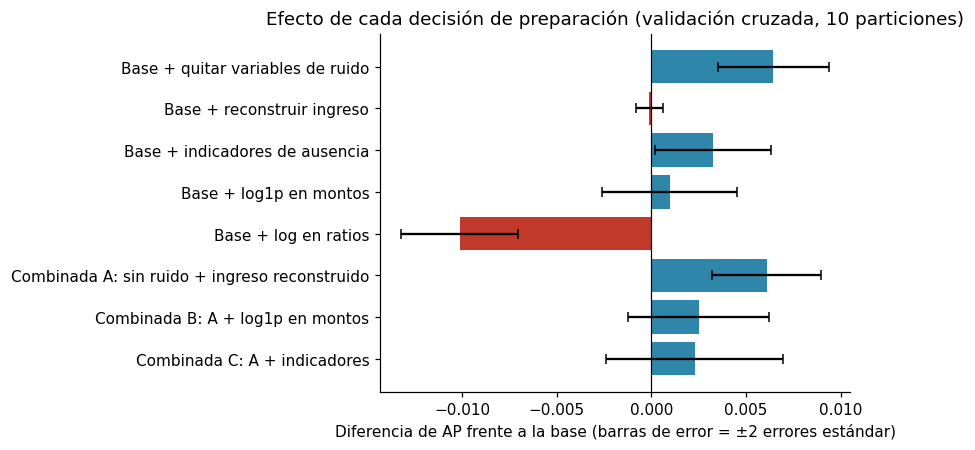

AP de la variante base en las 10 particiones: mínimo 0.325, máximo 0.407, desviación 0.023


In [22]:
fig, ax = plt.subplots(figsize=(8, 4.2))
c = comparacion.iloc[1:].iloc[::-1]
colores = ["#2e86ab" if d > 0 else "#c0392b" for d in c["dif_vs_base"]]
ax.barh(c.index, c["dif_vs_base"], xerr=2 * c["error_estandar"].astype(float), color=colores, capsize=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Diferencia de AP frente a la base (barras de error = ±2 errores estándar)")
ax.set_title("Efecto de cada decisión de preparación (validación cruzada, 10 particiones)")
plt.tight_layout(); plt.show()

base = ap_cv["Base (mediana + escala + one-hot)"]
print(f"AP de la variante base en las 10 particiones: mínimo {base.min():.3f}, máximo {base.max():.3f}, "
      f"desviación {base.std(ddof=1):.3f}")

- **Se adopta:** quitar las variables de ruido (+0,006 de AP, gana en 10 de 10) y reconstruir el ingreso (neutro en AP, pero imputación más fiel).
- **Se descarta:** logaritmo en ratios (−0,010; comprime la cola donde está la señal), indicadores de ausencia y logaritmo en montos (sin mejora).
- El AP de una misma variante oscila entre 0,33 y 0,41 según la partición: **diferencias de 0,01–0,02 no son concluyentes**.

### 4.2 Preprocesador elegido y evidencia de que no hay fuga

In [23]:
OPCIONES_ELEGIDAS = dict(quitar_ruido=True, reconstruir_ingreso=True)

filas = []
for nombre, opciones in [("Base", dict()), ("Elegida (A)", OPCIONES_ELEGIDAS)]:
    tuberia = Pipeline([("prep", construir_preprocesador(**opciones)), ("red", modelo_referencia())]).fit(X_train, y_train)
    p_tr, p_va = tuberia.predict_proba(X_train)[:, 1], tuberia.predict_proba(X_val)[:, 1]
    filas.append({"variante": nombre,
                  "AP_train": average_precision_score(y_train, p_tr), "AP_val": average_precision_score(y_val, p_va),
                  "ROC_AUC_val": roc_auc_score(y_val, p_va)})
display(pd.DataFrame(filas).set_index("variante"))
print(f"AP de un modelo aleatorio (prevalencia en validación): {y_val.mean():.4f}")

,AP_train,AP_val,ROC_AUC_val
variante,,,
Base,0.4281,0.4079,0.7312
Elegida (A),0.4291,0.4049,0.7267


AP de un modelo aleatorio (prevalencia en validación): 0.1806


In [24]:
preprocesador = construir_preprocesador(**OPCIONES_ELEGIDAS).fit(X_train)      # <- único ajuste, solo con entrenamiento
columnas = preprocesador.named_steps["columnas"].get_feature_names_out()
n_num = len(numericas) - len(VARIABLES_RUIDO)

conjuntos = {"entrenamiento": X_train, "validación": X_val, "final interno": X_final,
             "público": publico[predictoras], "privado": privado[predictoras]}
filas = []
for nombre, datos in conjuntos.items():
    Z = preprocesador.transform(datos)
    filas.append({"conjunto": nombre, "filas": Z.shape[0], "columnas": Z.shape[1], "faltantes": int(np.isnan(Z).sum()),
                  "media_numéricas (máx. |valor|)": np.abs(Z[:, :n_num].mean(axis=0)).max(),
                  "desviación_numéricas (rango)": f"{Z[:, :n_num].std(axis=0).min():.3f} - {Z[:, :n_num].std(axis=0).max():.3f}"})
display(pd.DataFrame(filas).set_index("conjunto"))

print(f"Columnas finales: {len(columnas)} ({n_num} numéricas + {len(columnas) - n_num} de one-hot)")
print(list(columnas))

,filas,columnas,faltantes,media_numéricas (máx. |valor|),desviación_numéricas (rango)
conjunto,,,,,
entrenamiento,14700,63,0,0.0000,1.000 - 1.000
validación,3150,63,0,0.0399,0.857 - 1.060
final interno,3150,63,0,0.0447,0.965 - 1.176
público,4500,63,0,0.0410,0.857 - 1.195
privado,4500,63,0,0.0415,0.978 - 1.150


Columnas finales: 63 (30 numéricas + 33 de one-hot)
['edad', 'antiguedad_negocio_anios', 'ingreso_mensual', 'deuda_total', 'monto_credito', 'plazo_meses', 'tasa_interes', 'score_crediticio', 'retrasos_12m', 'creditos_activos', 'consultas_crediticias_6m', 'saldo_promedio', 'ventas_anuales', 'hectareas_cultivadas', 'rendimiento_ton_ha', 'variabilidad_ingresos', 'perdidas_cosecha_pct', 'dependencia_cliente_principal', 'dias_mora_historica', 'ratio_deuda_ingreso', 'ratio_cuota_ingreso', 'antiguedad_banco_meses', 'numero_dependientes', 'transacciones_mensuales', 'uso_banca_digital_pct', 'indice_estacionalidad', 'temperatura_promedio', 'precipitacion_mm', 'indice_riesgo_climatico', 'distancia_mercado_km', 'region_Costa', 'region_Selva', 'region_Sierra', 'cultivo_principal_Arroz', 'cultivo_principal_Cacao', 'cultivo_principal_Cafe', 'cultivo_principal_Maiz', 'cultivo_principal_Palta', 'cultivo_principal_Papa', 'cultivo_principal_Uva', 'tipo_cliente_Microempresa', 'tipo_cliente_Pequena empresa

In [25]:
# Medianas aprendidas: provienen de entrenamiento, no del archivo completo
imputador = preprocesador.named_steps["columnas"].named_transformers_["num"].named_steps["imputar"]
nombres_num = preprocesador.named_steps["columnas"].transformers_[0][2]
medianas = pd.DataFrame({"mediana_aprendida": imputador.statistics_,
                         "mediana_solo_train": preparar_filas(X_train, reconstruir_ingreso=True)[nombres_num].median().values,
                         "mediana_archivo_completo": preparar_filas(X, reconstruir_ingreso=True)[nombres_num].median().values},
                        index=nombres_num).loc[["score_crediticio", "saldo_promedio", "precipitacion_mm", "rendimiento_ton_ha"]]
display(medianas)

# Categoría nunca vista: se codifica como ceros, sin error
fila_nueva = X_val.head(1).copy()
fila_nueva["cultivo_principal"] = "Quinua"
z = preprocesador.transform(fila_nueva)[0]
cols_cultivo = [i for i, c in enumerate(columnas) if c.startswith("cultivo_principal")]
print("Columnas one-hot de cultivo para una categoría desconocida ('Quinua'):", z[cols_cultivo])

,mediana_aprendida,mediana_solo_train,mediana_archivo_completo
score_crediticio,627.0000,627.0000,626.0000
saldo_promedio,"1,863.9900","1,863.9900","1,841.4900"
precipitacion_mm,83.1000,83.1000,83.8000
rendimiento_ton_ha,11.9500,11.9500,11.9900


Columnas one-hot de cultivo para una categoría desconocida ('Quinua'): [0. 0. 0. 0. 0. 0. 0.]


Media exactamente 0 solo en entrenamiento; medianas iguales a las de entrenamiento y no a las del archivo completo; 63 columnas y cero faltantes en todos los conjuntos; una categoría desconocida no produce error.

## 5. Baseline y experimentos con `MLPClassifier`
Cada configuración se entrena con 3 semillas y se registra con su configuración, tiempo y métricas. Se cambia un aspecto por experimento.

In [26]:
numericas_modelo = [c for c in numericas if c not in VARIABLES_RUIDO]       # numéricas que entran al modelo
Z_train, Z_val = preprocesador.transform(X_train), preprocesador.transform(X_val)   # preprocesador ajustado solo con entrenamiento
yt, yv = y_train.to_numpy(), y_val.to_numpy()
print("Entrenamiento:", Z_train.shape, "| Validación:", Z_val.shape)

Entrenamiento: (14700, 63) | Validación: (3150, 63)


In [27]:
registro = []

def experimento(codigo, descripcion, Z=None, y_ent=None, **config):
    """Entrena la configuración con 3 semillas y registra métricas en entrenamiento y validación."""
    Z = Z_train if Z is None else Z
    y_ent = yt if y_ent is None else y_ent
    ap_tr, ap_va, auc_va, epocas, prob_media = [], [], [], [], []
    t0 = time.time()
    for s in SEMILLAS:
        red = MLPClassifier(random_state=s, **config).fit(Z, y_ent)
        p_tr, p_va = red.predict_proba(Z_train)[:, 1], red.predict_proba(Z_val)[:, 1]   # siempre sobre los datos originales
        ap_tr.append(average_precision_score(yt, p_tr)); ap_va.append(average_precision_score(yv, p_va))
        auc_va.append(roc_auc_score(yv, p_va)); epocas.append(red.n_iter_); prob_media.append(p_va.mean())
    fila = {"exp": codigo, "descripcion": descripcion,
            "AP_train": np.mean(ap_tr), "AP_val": np.mean(ap_va), "AP_val_sd": np.std(ap_va, ddof=1),
            "brecha": np.mean(ap_tr) - np.mean(ap_va), "ROC_AUC_val": np.mean(auc_va),
            "epocas": int(np.mean(epocas)), "prob_media_val": np.mean(prob_media),
            "tiempo_s": round(time.time() - t0, 1), "semillas": str(SEMILLAS), "config": str(config)}
    registro.append(fila)
    print(f"{codigo:4s} {descripcion:52s} AP train {fila['AP_train']:.3f} | AP val {fila['AP_val']:.4f} ± {fila['AP_val_sd']:.4f}"
          f" | épocas {fila['epocas']:3d} | {fila['tiempo_s']:.0f} s")
    return fila

### 5.1 Baseline y bloque A: capacidad y regularización

In [28]:
m0 = experimento("M0", "Baseline: (16,), valores por defecto", hidden_layer_sizes=(16,))
print(f"\nReferencias: AP de un modelo aleatorio = {yv.mean():.3f} | AP del modelo de referencia de la Parte 2 = 0,405")

M0   Baseline: (16,), valores por defecto                 AP train 0.515 | AP val 0.3490 ± 0.0223 | épocas 200 | 22 s

Referencias: AP de un modelo aleatorio = 0.181 | AP del modelo de referencia de la Parte 2 = 0,405


In [29]:
experimento("M1", "Capacidad: (64, 32)",                      hidden_layer_sizes=(64, 32))
experimento("M2", "L2: (16,) con alpha=1",                    hidden_layer_sizes=(16,), alpha=1.0)
experimento("M3", "Capacidad + L2: (64, 32) con alpha=3",     hidden_layer_sizes=(64, 32), alpha=3.0)
experimento("M4", "Menos épocas: (16,) con max_iter=20",      hidden_layer_sizes=(16,), max_iter=20)
experimento("M5", "early_stopping de sklearn: (16,)",         hidden_layer_sizes=(16,), early_stopping=True);

M1   Capacidad: (64, 32)                                  AP train 0.999 | AP val 0.2662 ± 0.0125 | épocas 200 | 78 s
M2   L2: (16,) con alpha=1                                AP train 0.427 | AP val 0.4091 ± 0.0045 | épocas  80 | 9 s
M3   Capacidad + L2: (64, 32) con alpha=3                 AP train 0.389 | AP val 0.4020 ± 0.0006 | épocas  46 | 16 s
M4   Menos épocas: (16,) con max_iter=20                  AP train 0.423 | AP val 0.3959 ± 0.0105 | épocas  20 | 2 s
M5   early_stopping de sklearn: (16,)                     AP train 0.372 | AP val 0.3764 ± 0.0470 | épocas  19 | 5 s


El baseline sobreajusta (AP 0,51 en entrenamiento y 0,35 en validación) y la red grande memoriza (1,00 y 0,27). La **L2 fuerte (M2)** cierra la brecha y sube la validación a 0,41. El `early_stopping` de Scikit-learn es inestable porque decide con accuracy.

### 5.2 Curva de validación de `alpha` y curvas de aprendizaje

alpha,0.0001,0.0100,0.1000,0.3000,1.0000,3.0000,10.0000,30.0000
AP_train,0.5151,0.5135,0.5126,0.4997,0.4274,0.3903,0.3814,0.3577
AP_val,0.3490,0.3568,0.3603,0.3810,0.4091,0.4034,0.3983,0.3748


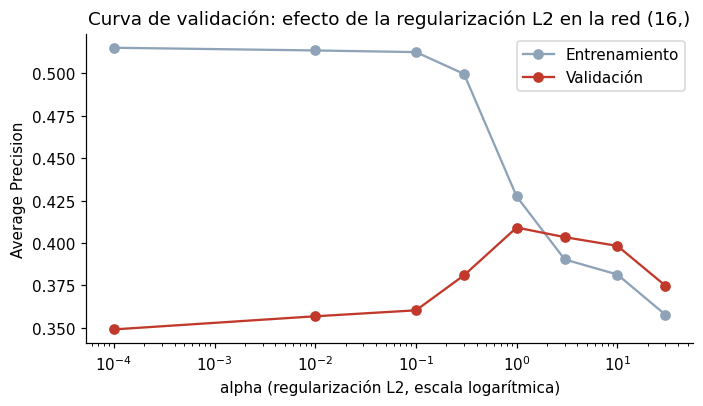

In [30]:
alphas = [1e-4, 1e-2, 1e-1, 0.3, 1, 3, 10, 30]
curva = []
for a in alphas:
    tr, va = [], []
    for s in SEMILLAS:
        red = MLPClassifier(hidden_layer_sizes=(16,), alpha=a, random_state=s).fit(Z_train, yt)
        tr.append(average_precision_score(yt, red.predict_proba(Z_train)[:, 1]))
        va.append(average_precision_score(yv, red.predict_proba(Z_val)[:, 1]))
    curva.append({"alpha": a, "AP_train": np.mean(tr), "AP_val": np.mean(va)})
curva = pd.DataFrame(curva)
display(curva.set_index("alpha").T)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(curva["alpha"], curva["AP_train"], marker="o", color="#8fa3b8", label="Entrenamiento")
ax.plot(curva["alpha"], curva["AP_val"], marker="o", color="#c0392b", label="Validación")
ax.set_xscale("log"); ax.set_xlabel("alpha (regularización L2, escala logarítmica)"); ax.set_ylabel("Average Precision")
ax.set_title("Curva de validación: efecto de la regularización L2 en la red (16,)"); ax.legend()
plt.tight_layout(); plt.show()

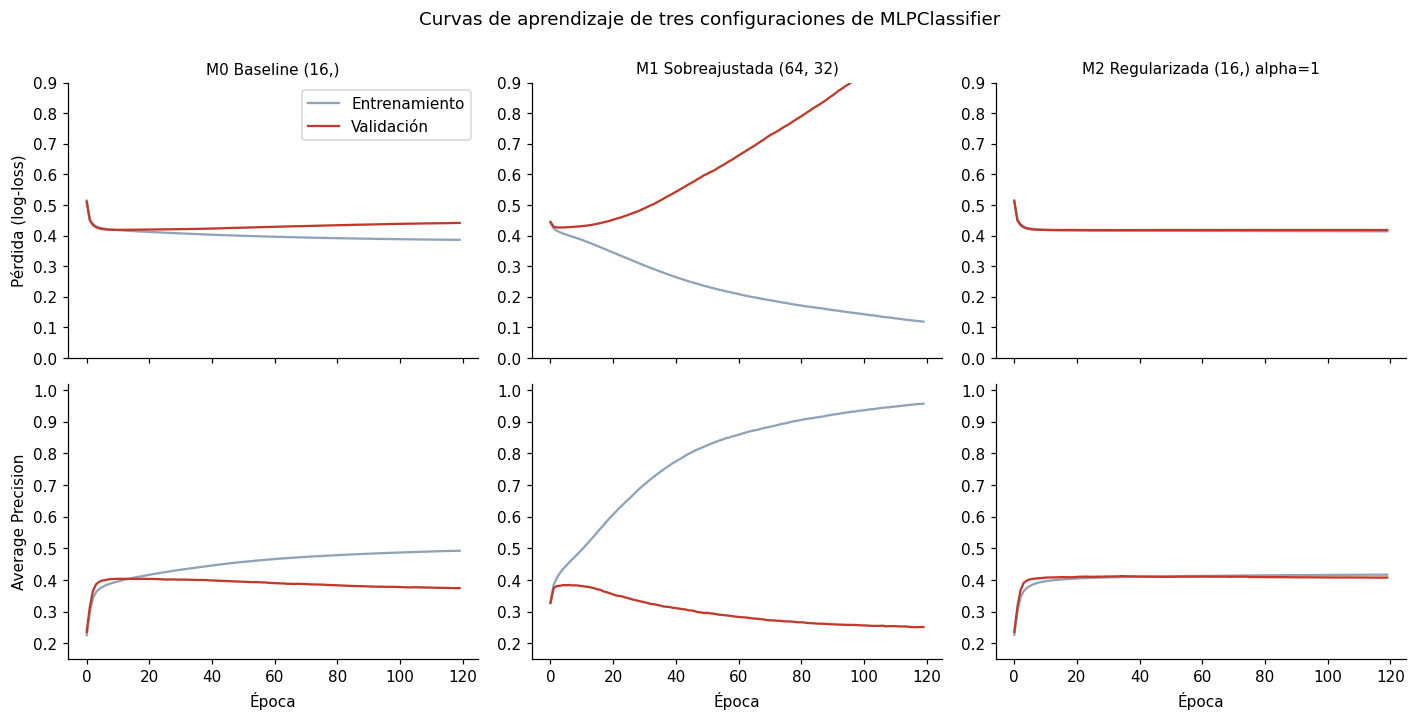

,mejor época (mín. pérdida val),pérdida val mínima,pérdida val final,pérdida train final,AP val máximo,AP val final
"M0 Baseline (16,)",11.0000,0.4191,0.4416,0.3863,0.4040,0.3744
"M1 Sobreajustada (64, 32)",4.0000,0.4267,1.0771,0.1191,0.3845,0.2516
"M2 Regularizada (16,) alpha=1",33.0000,0.4182,0.4184,0.4142,0.4124,0.4079


In [31]:
def curva_por_epoca(config, epocas=120):
    red = MLPClassifier(random_state=SEMILLA, **config)
    h = {"loss_train": [], "loss_val": [], "ap_train": [], "ap_val": []}
    for _ in range(epocas):
        red.partial_fit(Z_train, yt, classes=[0, 1])           # una época
        p_tr, p_va = red.predict_proba(Z_train)[:, 1], red.predict_proba(Z_val)[:, 1]
        h["loss_train"].append(log_loss(yt, p_tr)); h["loss_val"].append(log_loss(yv, p_va))
        h["ap_train"].append(average_precision_score(yt, p_tr)); h["ap_val"].append(average_precision_score(yv, p_va))
    return pd.DataFrame(h)

configs_curva = {"M0 Baseline (16,)": dict(hidden_layer_sizes=(16,)),
                 "M1 Sobreajustada (64, 32)": dict(hidden_layer_sizes=(64, 32)),
                 "M2 Regularizada (16,) alpha=1": dict(hidden_layer_sizes=(16,), alpha=1.0)}
historias = {n: curva_por_epoca(c) for n, c in configs_curva.items()}

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
for j, (nombre, h) in enumerate(historias.items()):
    axes[0, j].plot(h["loss_train"], color="#8fa3b8", label="Entrenamiento"); axes[0, j].plot(h["loss_val"], color="#c0392b", label="Validación")
    axes[0, j].set_title(nombre, fontsize=10); axes[0, j].set_ylim(0.0, 0.9)
    axes[1, j].plot(h["ap_train"], color="#8fa3b8"); axes[1, j].plot(h["ap_val"], color="#c0392b")
    axes[1, j].set_ylim(0.15, 1.02); axes[1, j].set_xlabel("Época")
axes[0, 0].set_ylabel("Pérdida (log-loss)"); axes[1, 0].set_ylabel("Average Precision"); axes[0, 0].legend()
plt.suptitle("Curvas de aprendizaje de tres configuraciones de MLPClassifier", y=1.0); plt.tight_layout(); plt.show()

resumen_curvas = pd.DataFrame({n: {"mejor época (mín. pérdida val)": int(h["loss_val"].idxmin()) + 1,
                                   "pérdida val mínima": h["loss_val"].min(), "pérdida val final": h["loss_val"].iloc[-1],
                                   "pérdida train final": h["loss_train"].iloc[-1],
                                   "AP val máximo": h["ap_val"].max(), "AP val final": h["ap_val"].iloc[-1]}
                               for n, h in historias.items()}).T
display(resumen_curvas)

Con `alpha` pequeño hay sobreajuste; entre 1 y 3, ajuste adecuado; desde 30, subajuste. En M0 y M1 la pérdida de validación sube mientras la de entrenamiento baja; en M2 ambas se estabilizan juntas.

### 5.3 Bloque B: optimización y forma de la red

In [32]:
base = dict(hidden_layer_sizes=(16,), alpha=1.0)
experimento("M6",  "Tasa de aprendizaje 0,01",    **{**base, "learning_rate_init": 1e-2})
experimento("M7",  "Tasa de aprendizaje 0,0001",  **{**base, "learning_rate_init": 1e-4})
experimento("M8",  "Activación tanh",             **{**base, "activation": "tanh"})
experimento("M9",  "Más ancho: (32,)",            **{**base, "hidden_layer_sizes": (32,)})
experimento("M10", "Lote de 64",                  **{**base, "batch_size": 64})
experimento("M11", "Lote de 512",                 **{**base, "batch_size": 512});

M6   Tasa de aprendizaje 0,01                             AP train 0.391 | AP val 0.4005 ± 0.0017 | épocas  41 | 4 s
M7   Tasa de aprendizaje 0,0001                           AP train 0.409 | AP val 0.4059 ± 0.0074 | épocas 154 | 17 s
M8   Activación tanh                                      AP train 0.396 | AP val 0.4091 ± 0.0019 | épocas  65 | 8 s
M9   Más ancho: (32,)                                     AP train 0.441 | AP val 0.4045 ± 0.0027 | épocas  92 | 12 s
M10  Lote de 64                                           AP train 0.389 | AP val 0.4034 ± 0.0004 | épocas  43 | 10 s
M11  Lote de 512                                          AP train 0.479 | AP val 0.3874 ± 0.0026 | épocas 179 | 12 s


Tasa de aprendizaje, activación, ancho y lote dejan el AP entre 0,39 y 0,41: dentro del ruido de la métrica.

### 5.4 Desbalance: sobremuestreo (solo sobre entrenamiento)

In [33]:
rng = np.random.default_rng(SEMILLA)
positivos = np.where(yt == 1)[0]
extra = rng.choice(positivos, size=(yt == 0).sum() - len(positivos), replace=True)    # copias de incumplidores
indices_os = rng.permutation(np.concatenate([np.arange(len(yt)), extra]))
Z_os, y_os = Z_train[indices_os], yt[indices_os]
print(f"Entrenamiento original     : {len(yt):,} filas, {yt.mean():.1%} de positivos")
print(f"Entrenamiento sobremuestreado: {len(y_os):,} filas, {y_os.mean():.1%} de positivos")
print(f"Validación (sin cambios)   : {len(yv):,} filas, {yv.mean():.1%} de positivos\n")

experimento("M12", "Sobremuestreo + (16,) alpha=1", Z=Z_os, y_ent=y_os, hidden_layer_sizes=(16,), alpha=1.0)
experimento("M13", "Sobremuestreo + (16,) alpha=2", Z=Z_os, y_ent=y_os, hidden_layer_sizes=(16,), alpha=2.0)

desbalance = pd.DataFrame(registro).set_index("exp").loc[["M2", "M12", "M13"], ["descripcion", "AP_train", "AP_val", "AP_val_sd", "ROC_AUC_val", "prob_media_val"]]
display(desbalance)
print(f"Prevalencia real en validación: {yv.mean():.3f}")

Entrenamiento original     : 14,700 filas, 18.0% de positivos
Entrenamiento sobremuestreado: 24,094 filas, 50.0% de positivos
Validación (sin cambios)   : 3,150 filas, 18.1% de positivos

M12  Sobremuestreo + (16,) alpha=1                        AP train 0.447 | AP val 0.3909 ± 0.0100 | épocas  97 | 18 s
M13  Sobremuestreo + (16,) alpha=2                        AP train 0.414 | AP val 0.4026 ± 0.0038 | épocas  67 | 12 s


,descripcion,AP_train,AP_val,AP_val_sd,ROC_AUC_val,prob_media_val
exp,,,,,,
M2,"L2: (16,) con alpha=1",0.4274,0.4091,0.0045,0.7285,0.1846
M12,"Sobremuestreo + (16,) alpha=1",0.4469,0.3909,0.0100,0.7183,0.4299
M13,"Sobremuestreo + (16,) alpha=2",0.4139,0.4026,0.0038,0.7287,0.4468


Prevalencia real en validación: 0.181


El sobremuestreo **no mejora el AP** y descalibra: la probabilidad media predicha pasa de 0,18 a 0,43–0,45. Se entrena sin tratamiento.

### 5.5 Tabla de experimentos con `MLPClassifier`

,descripcion,AP_train,AP_val,AP_val_sd,brecha,ROC_AUC_val,epocas,tiempo_s
exp,,,,,,,,
M2,"L2: (16,) con alpha=1",0.4274,0.4091,0.0045,0.0183,0.7285,80,9.2000
M8,Activación tanh,0.3959,0.4091,0.0019,-0.0132,0.7302,65,8.1000
M7,"Tasa de aprendizaje 0,0001",0.4094,0.4059,0.0074,0.0035,0.7286,154,16.6000
M9,"Más ancho: (32,)",0.4406,0.4045,0.0027,0.0361,0.7260,92,12.5000
M10,Lote de 64,0.3889,0.4034,0.0004,-0.0145,0.7288,43,9.5000
M13,"Sobremuestreo + (16,) alpha=2",0.4139,0.4026,0.0038,0.0113,0.7287,67,11.5000
M3,"Capacidad + L2: (64, 32) con alpha=3",0.3890,0.4020,0.0006,-0.0129,0.7294,46,16.5000
M6,"Tasa de aprendizaje 0,01",0.3912,0.4005,0.0017,-0.0093,0.7268,41,4.0000
M4,"Menos épocas: (16,) con max_iter=20",0.4227,0.3959,0.0105,0.0269,0.7217,20,2.1000


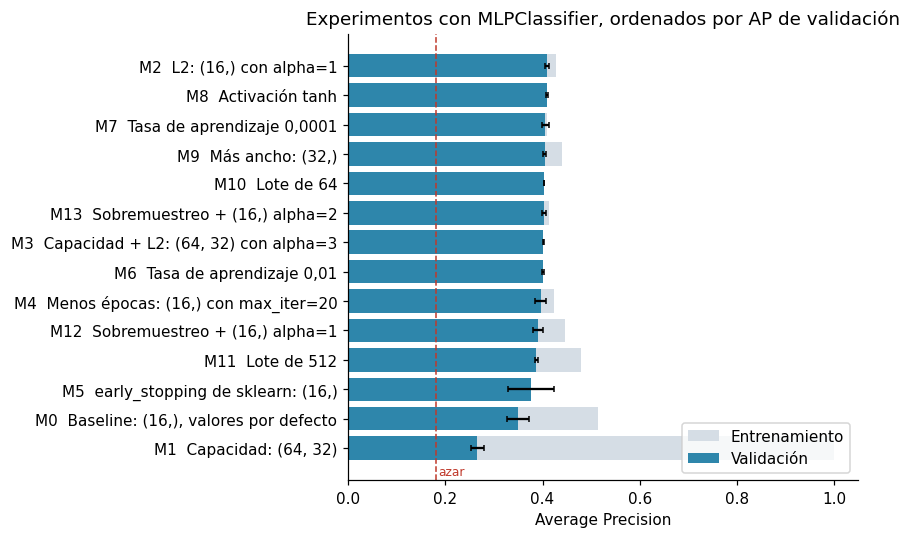

In [34]:
tabla = pd.DataFrame(registro).set_index("exp")
tabla.to_csv("resultados_mlp_sklearn.csv")                    # se reutiliza en la comparación final (sección 7)
orden = tabla.sort_values("AP_val", ascending=False)
display(orden[["descripcion", "AP_train", "AP_val", "AP_val_sd", "brecha", "ROC_AUC_val", "epocas", "tiempo_s"]])

fig, ax = plt.subplots(figsize=(8, 5))
o = orden.iloc[::-1]
ax.barh(o.index + "  " + o["descripcion"].str.slice(0, 38), o["AP_train"], color="#d5dde5", label="Entrenamiento")
ax.barh(o.index + "  " + o["descripcion"].str.slice(0, 38), o["AP_val"], xerr=o["AP_val_sd"], color="#2e86ab", label="Validación", capsize=2)
ax.axvline(yv.mean(), color="#c0392b", ls="--", lw=1); ax.text(yv.mean() + 0.005, -0.9, "azar", color="#c0392b", fontsize=8)
ax.set_xlabel("Average Precision"); ax.set_title("Experimentos con MLPClassifier, ordenados por AP de validación"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

Configuración elegida en Scikit-learn: **M2** (16 neuronas, `alpha=1`), la más simple del grupo de cabeza.

## 6. Red densa con Keras y diagnóstico de ajuste
Salida sigmoide y entropía cruzada binaria. Se añaden las medidas que Scikit-learn no ofrece: dropout, L1, early stopping sobre la pérdida de validación y `class_weight`.

In [35]:
Z_train, Z_val = Z_train.astype("float32"), Z_val.astype("float32")        # Keras trabaja con float32
yt, yv = yt.astype("float32"), yv.astype("float32")

In [36]:
def construir_red(capas=(16,), l2=0.0, l1=0.0, dropout=0.0, tasa=1e-3, activacion="relu", optimizador="adam"):
    reg = regularizers.L1L2(l1=l1, l2=l2) if (l1 or l2) else None
    red = keras.Sequential([keras.Input(shape=(Z_train.shape[1],))])
    for neuronas in capas:
        red.add(layers.Dense(neuronas, activation=activacion, kernel_regularizer=reg))
        if dropout:
            red.add(layers.Dropout(dropout))
    red.add(layers.Dense(1, activation="sigmoid"))                       # salida: probabilidad de incumplimiento
    opt = {"adam": keras.optimizers.Adam(tasa), "sgd": keras.optimizers.SGD(tasa, momentum=0.9)}[optimizador]
    red.compile(optimizer=opt, loss="binary_crossentropy")
    return red

def predecir(red, Z):
    return red.predict(Z, batch_size=4096, verbose=0).ravel()

registro, historiales, probabilidades = [], {}, {}

def experimento(codigo, descripcion, epocas=60, lote=128, paciencia=None, pesos_clase=None, Ztr=None, Zva=None, **config):
    """Entrena la configuración con 3 semillas y registra métricas en entrenamiento y validación."""
    Ztr = Z_train if Ztr is None else Ztr
    Zva = Z_val if Zva is None else Zva
    ap_tr, ap_va, auc_va, ep, pm, probs = [], [], [], [], [], []
    t0 = time.time()
    for s in SEMILLAS:
        keras.utils.set_random_seed(s)                                   # fija semillas de Python, NumPy y TensorFlow
        red = construir_red(**config)
        paradas = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia, restore_best_weights=True)] if paciencia else []
        h = red.fit(Ztr, yt, validation_data=(Zva, yv), epochs=epocas, batch_size=lote,
                    callbacks=paradas, class_weight=pesos_clase, verbose=0)
        p_tr, p_va = predecir(red, Ztr), predecir(red, Zva)
        ap_tr.append(average_precision_score(yt, p_tr)); ap_va.append(average_precision_score(yv, p_va))
        auc_va.append(roc_auc_score(yv, p_va)); ep.append(len(h.history["loss"])); pm.append(p_va.mean()); probs.append(p_va)
        if s == SEMILLAS[0]:
            historiales[codigo] = h.history
    probabilidades[codigo] = np.array(probs)
    fila = {"exp": codigo, "descripcion": descripcion, "AP_train": np.mean(ap_tr), "AP_val": np.mean(ap_va),
            "AP_val_sd": np.std(ap_va, ddof=1), "brecha": np.mean(ap_tr) - np.mean(ap_va), "ROC_AUC_val": np.mean(auc_va),
            "epocas": int(np.mean(ep)), "prob_media_val": np.mean(pm), "parametros": red.count_params(),
            "tiempo_s": round(time.time() - t0, 1), "semillas": str(SEMILLAS),
            "config": str({**config, "epocas_max": epocas, "lote": lote, "paciencia": paciencia, "pesos_clase": pesos_clase is not None})}
    registro.append(fila)
    print(f"{codigo:4s} {descripcion:50s} AP train {fila['AP_train']:.3f} | AP val {fila['AP_val']:.4f} ± {fila['AP_val_sd']:.4f}"
          f" | épocas {fila['epocas']:3d} | {fila['tiempo_s']:.0f} s")
    return fila

construir_red().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,041 (4.07 KB)

 Trainable params: 1,041 (4.07 KB)

 Non-trainable params: 0 (0.00 B)

### 6.1 Baseline, red sobreajustada y red regularizada

In [37]:
experimento("K0", "Baseline: (16,), sin regularización")
experimento("K1", "Sobreajustada: (256, 128, 64), sin regularización", capas=(256, 128, 64))
experimento("K2", "Regularizada: (16,) con L2 = 0,01", l2=0.01);

K0   Baseline: (16,), sin regularización                AP train 0.482 | AP val 0.3698 ± 0.0198 | épocas  60 | 65 s
K1   Sobreajustada: (256, 128, 64), sin regularización  AP train 1.000 | AP val 0.2670 ± 0.0036 | épocas  60 | 114 s
K2   Regularizada: (16,) con L2 = 0,01                  AP train 0.423 | AP val 0.4049 ± 0.0034 | épocas  60 | 66 s


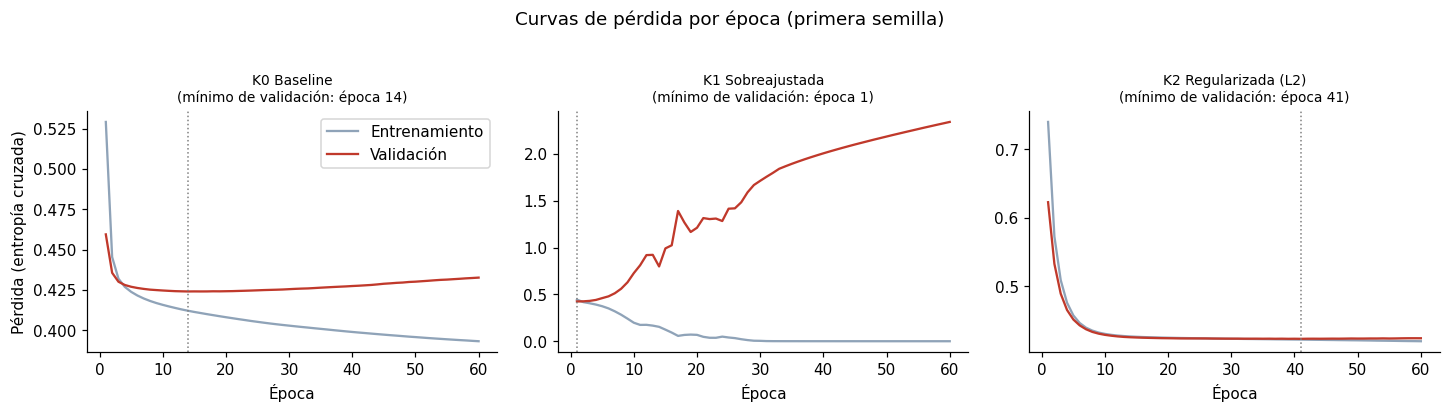

,pérdida train final,pérdida val mínima,época del mínimo,pérdida val final,AP_train,AP_val,brecha,parametros
K0,0.3931,0.4240,14.0000,0.4326,0.4820,0.3698,0.1122,1041
K1,0.0001,0.4244,1.0000,2.3400,1.0000,0.2670,0.7330,57601
K2,0.4201,0.4237,41.0000,0.4245,0.4227,0.4049,0.0178,1041


In [38]:
def graficar_curvas(codigos, titulos, titulo_general):
    fig, axes = plt.subplots(1, len(codigos), figsize=(4.4 * len(codigos), 3.6))
    for ax, c, tt in zip(np.atleast_1d(axes), codigos, titulos):
        h = historiales[c]; ep = range(1, len(h["loss"]) + 1)
        ax.plot(ep, h["loss"], color="#8fa3b8", label="Entrenamiento")
        ax.plot(ep, h["val_loss"], color="#c0392b", label="Validación")
        mejor = int(np.argmin(h["val_loss"])) + 1
        ax.axvline(mejor, color="gray", ls=":", lw=1)
        ax.set_title(f"{tt}\n(mínimo de validación: época {mejor})", fontsize=9); ax.set_xlabel("Época")
    np.atleast_1d(axes)[0].set_ylabel("Pérdida (entropía cruzada)"); np.atleast_1d(axes)[0].legend()
    plt.suptitle(titulo_general, y=1.03); plt.tight_layout(); plt.show()

graficar_curvas(["K0", "K1", "K2"], ["K0 Baseline", "K1 Sobreajustada", "K2 Regularizada (L2)"],
                "Curvas de pérdida por época (primera semilla)")

diag = pd.DataFrame({c: {"pérdida train final": historiales[c]["loss"][-1], "pérdida val mínima": min(historiales[c]["val_loss"]),
                         "época del mínimo": int(np.argmin(historiales[c]["val_loss"])) + 1, "pérdida val final": historiales[c]["val_loss"][-1]}
                     for c in ["K0", "K1", "K2"]}).T
display(diag.join(pd.DataFrame(registro).set_index("exp")[["AP_train", "AP_val", "brecha", "parametros"]]))

- **K0 Baseline:** sobreajuste moderado; el mínimo de validación llega en la época 14.
- **K1 Sobreajustada:** el mínimo de validación está en la época 1; después memoriza (AP 1,00 en entrenamiento, 0,27 en validación).
- **K2 Regularizada (L2):** las dos curvas se estabilizan juntas; AP de validación 0,405.

### 6.2 Medidas de control: dropout, early stopping y L2

K3   Dropout 0,5: (64, 32)                              AP train 0.579 | AP val 0.3779 ± 0.0074 | épocas  60 | 79 s
K4   Early stopping: (64, 32)                           AP train 0.436 | AP val 0.4024 ± 0.0024 | épocas  14 | 20 s
K5   L2 0,01 + early stopping: (16,)                    AP train 0.411 | AP val 0.4069 ± 0.0014 | épocas  44 | 49 s
K6   Dropout 0,3 + L2 0,01 + early stopping: (32,)      AP train 0.404 | AP val 0.4074 ± 0.0016 | épocas  39 | 48 s


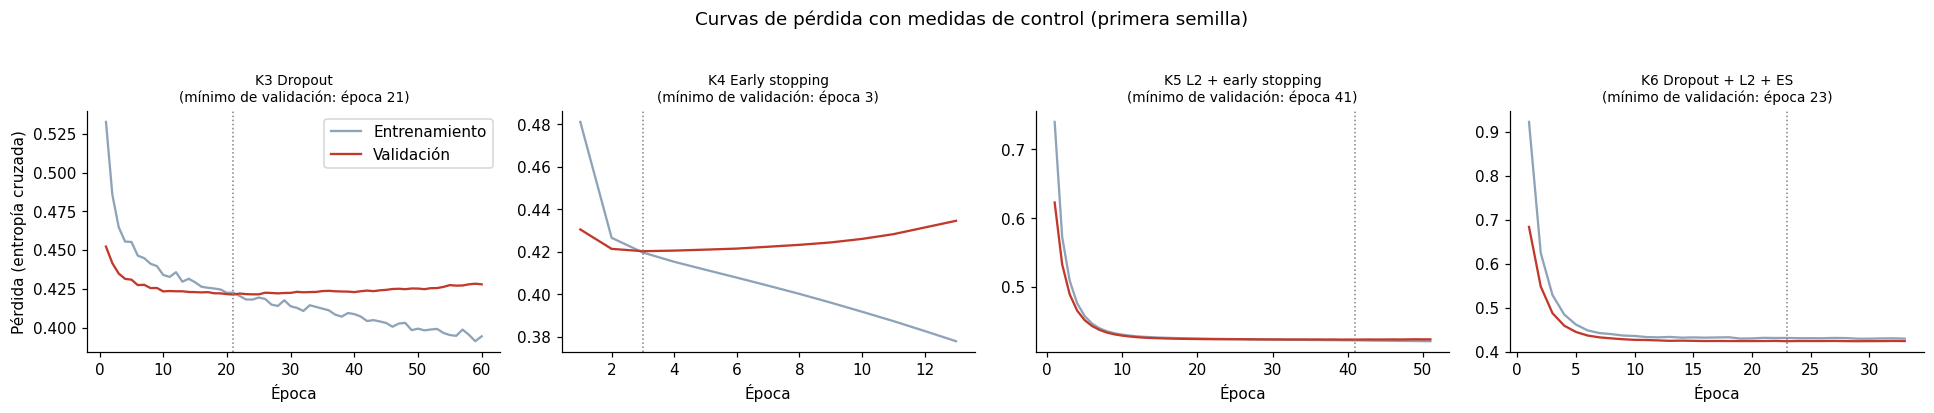

In [39]:
experimento("K3", "Dropout 0,5: (64, 32)",                          capas=(64, 32), dropout=0.5)
experimento("K4", "Early stopping: (64, 32)",                       capas=(64, 32), paciencia=10, epocas=150)
experimento("K5", "L2 0,01 + early stopping: (16,)",                l2=0.01, paciencia=10, epocas=150)
experimento("K6", "Dropout 0,3 + L2 0,01 + early stopping: (32,)",  capas=(32,), dropout=0.3, l2=0.01, paciencia=10, epocas=150)

graficar_curvas(["K3", "K4", "K5", "K6"], ["K3 Dropout", "K4 Early stopping", "K5 L2 + early stopping", "K6 Dropout + L2 + ES"],
                "Curvas de pérdida con medidas de control (primera semilla)")

El dropout solo no basta (brecha de 0,20). Early stopping y L2 sí controlan el sobreajuste; **K5** (L2 + early stopping) es la combinación más simple del grupo de cabeza.

### 6.3 Optimización y L1

In [40]:
base = dict(l2=0.01, paciencia=10, epocas=150)
experimento("K7",  "Tasa de aprendizaje 0,01",        **{**base, "tasa": 0.01})
experimento("K8",  "Lotes de 512",                   **{**base, "lote": 512})
experimento("K9",  "Optimizador SGD con momento",    **{**base, "optimizador": "sgd", "tasa": 0.01})
experimento("K10", "Activación tanh",                **{**base, "activacion": "tanh"})
experimento("K11", "L1 = 0,001 en lugar de L2",      **{**base, "l2": 0.0, "l1": 0.001});

K7   Tasa de aprendizaje 0,01                           AP train 0.382 | AP val 0.3965 ± 0.0030 | épocas 109 | 117 s
K8   Lotes de 512                                       AP train 0.414 | AP val 0.4088 ± 0.0020 | épocas 114 | 61 s
K9   Optimizador SGD con momento                        AP train 0.406 | AP val 0.4030 ± 0.0039 | épocas  31 | 34 s
K10  Activación tanh                                    AP train 0.394 | AP val 0.4088 ± 0.0015 | épocas 150 | 162 s
K11  L1 = 0,001 en lugar de L2                          AP train 0.408 | AP val 0.4087 ± 0.0019 | épocas  75 | 82 s


Solo empeora la tasa de aprendizaje 0,01. Lote, optimizador, activación y L1 quedan dentro del ruido.

### 6.4 Desbalance: `class_weight`

In [41]:
peso_positivo = (1 - yt.mean()) / yt.mean()
print(f"Peso de la clase positiva: {peso_positivo:.2f} (clase negativa: 1,00)\n")
experimento("K12", "class_weight balanceado", pesos_clase={0: 1.0, 1: float(peso_positivo)}, **base)

tabla_parcial = pd.DataFrame(registro).set_index("exp")
display(tabla_parcial.loc[["K5", "K12"], ["descripcion", "AP_train", "AP_val", "AP_val_sd", "ROC_AUC_val", "prob_media_val"]])
print(f"Prevalencia real en validación: {yv.mean():.3f}")

Peso de la clase positiva: 4.54 (clase negativa: 1,00)

K12  class_weight balanceado                            AP train 0.419 | AP val 0.4054 ± 0.0013 | épocas  35 | 42 s


,descripcion,AP_train,AP_val,AP_val_sd,ROC_AUC_val,prob_media_val
exp,,,,,,
K5,"L2 0,01 + early stopping: (16,)",0.4108,0.4069,0.0014,0.7305,0.1799
K12,class_weight balanceado,0.4186,0.4054,0.0013,0.7269,0.4479


Prevalencia real en validación: 0.181


`class_weight` no mejora el AP y sube la probabilidad media predicha a 0,45. Se confirma la decisión de no tratar el desbalance.

### 6.5 Logaritmo en montos y ensamble

In [42]:
prep_log = construir_preprocesador(**OPCIONES_ELEGIDAS, log_montos=True).fit(X_train)
Z_train_log = prep_log.transform(X_train).astype("float32")
Z_val_log   = prep_log.transform(X_val).astype("float32")
idx_montos = [numericas_modelo.index(c) for c in VARIABLES_LOG1P]              # posición de los montos en la matriz sin log
print("Valor estandarizado máximo en las variables de monto -> sin log:", round(float(Z_train[:, idx_montos].max()), 1),
      "| con log1p:", round(float(np.abs(Z_train_log[:, 24:30]).max()), 1), "\n")
experimento("K13", "K5 con log1p en montos", Ztr=Z_train_log, Zva=Z_val_log, **base);

Valor estandarizado máximo en las variables de monto -> sin log: 27.0 | con log1p: 4.3 

K13  K5 con log1p en montos                             AP train 0.410 | AP val 0.4078 ± 0.0018 | épocas  44 | 50 s


In [43]:
t0 = time.time()
probs_ensamble = list(probabilidades["K5"])
for s in range(SEMILLA + 3, SEMILLA + 8):
    keras.utils.set_random_seed(s)
    red = construir_red(l2=0.01)
    red.fit(Z_train, yt, validation_data=(Z_val, yv), epochs=150, batch_size=128, verbose=0,
            callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)])
    probs_ensamble.append(predecir(red, Z_val))
probs_ensamble = np.array(probs_ensamble)

ap_individual = [average_precision_score(yv, p) for p in probs_ensamble]
curva_ens = [average_precision_score(yv, probs_ensamble[:k].mean(axis=0)) for k in range(1, len(probs_ensamble) + 1)]
print(f"AP de las 8 redes individuales: media {np.mean(ap_individual):.4f}, mínimo {np.min(ap_individual):.4f}, máximo {np.max(ap_individual):.4f}")
print("AP del promedio de las k primeras redes:", " | ".join(f"k={k}: {v:.4f}" for k, v in enumerate(curva_ens, 1)))
print(f"Correlación media entre las predicciones de dos redes: {np.corrcoef(probs_ensamble)[np.triu_indices(8, 1)].mean():.3f}")

p_ens = probs_ensamble.mean(axis=0)
registro.append({"exp": "K14", "descripcion": "Ensamble: promedio de 8 redes K5", "AP_train": np.nan, "AP_val": curva_ens[-1],
                 "AP_val_sd": np.nan, "brecha": np.nan, "ROC_AUC_val": roc_auc_score(yv, p_ens), "epocas": np.nan,
                 "prob_media_val": p_ens.mean(), "parametros": 8 * 1041, "tiempo_s": round(time.time() - t0, 1),
                 "semillas": f"{SEMILLA} a {SEMILLA + 7}", "config": "promedio de probabilidades de 8 redes K5"})

AP de las 8 redes individuales: media 0.4068, mínimo 0.4041, máximo 0.4098
AP del promedio de las k primeras redes: k=1: 0.4079 | k=2: 0.4096 | k=3: 0.4100 | k=4: 0.4091 | k=5: 0.4093 | k=6: 0.4105 | k=7: 0.4104 | k=8: 0.4099
Correlación media entre las predicciones de dos redes: 0.977


El logaritmo en montos no cambia el AP. El ensamble de 8 redes gana poco (+0,003) porque las redes se parecen mucho, pero elimina la dependencia de una semilla.

### 6.6 Tabla de experimentos con Keras

,descripcion,AP_train,AP_val,AP_val_sd,brecha,ROC_AUC_val,epocas,parametros,tiempo_s
exp,,,,,,,,,
K14,Ensamble: promedio de 8 redes K5,NaN,0.4099,NaN,NaN,0.7310,NaN,8328,80.3000
K8,Lotes de 512,0.4141,0.4088,0.0020,0.0053,0.7306,114.0000,1041,60.7000
K10,Activación tanh,0.3943,0.4088,0.0015,-0.0145,0.7309,150.0000,1041,162.4000
K11,"L1 = 0,001 en lugar de L2",0.4084,0.4087,0.0019,-0.0003,0.7261,75.0000,1041,82.3000
K13,K5 con log1p en montos,0.4096,0.4078,0.0018,0.0019,0.7293,44.0000,1041,50.2000
K6,"Dropout 0,3 + L2 0,01 + early stopping: (32,)",0.4038,0.4074,0.0016,-0.0035,0.7313,39.0000,2081,48.1000
K5,"L2 0,01 + early stopping: (16,)",0.4108,0.4069,0.0014,0.0039,0.7305,44.0000,1041,48.9000
K12,class_weight balanceado,0.4186,0.4054,0.0013,0.0132,0.7269,35.0000,1041,42.0000
K2,"Regularizada: (16,) con L2 = 0,01",0.4227,0.4049,0.0034,0.0178,0.7287,60.0000,1041,66.5000


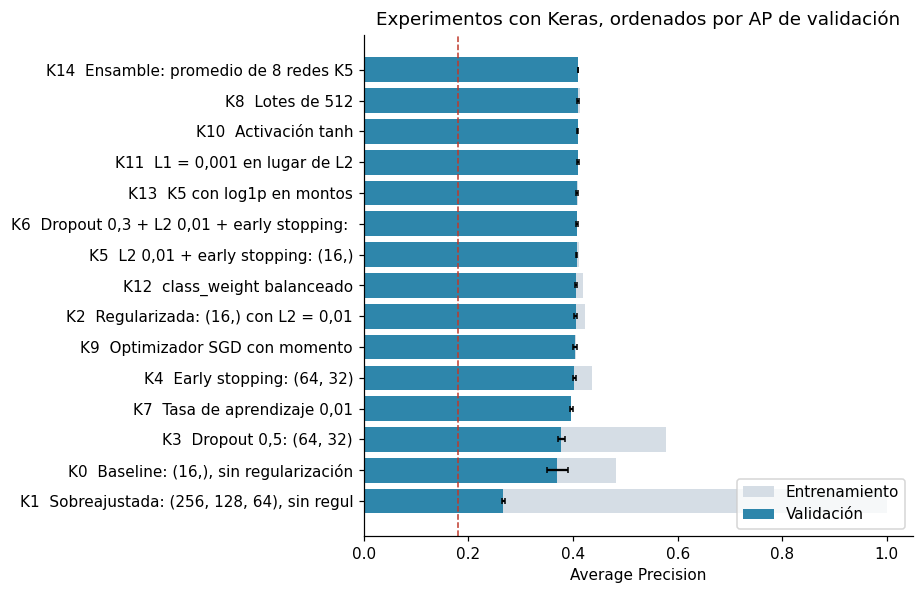

,MLPClassifier (M2),Keras (K5)
AP_train,0.4274,0.4108
AP_val,0.4091,0.4069
ROC_AUC_val,0.7285,0.7305
tiempo_s,9.2000,48.9000


In [44]:
tabla = pd.DataFrame(registro).set_index("exp")
tabla.to_csv("resultados_keras.csv")                          # se reutiliza en la comparación final (sección 7)
orden = tabla.sort_values("AP_val", ascending=False)
display(orden[["descripcion", "AP_train", "AP_val", "AP_val_sd", "brecha", "ROC_AUC_val", "epocas", "parametros", "tiempo_s"]])

fig, ax = plt.subplots(figsize=(8.5, 5.5))
o = orden.iloc[::-1]; etiquetas = o.index + "  " + o["descripcion"].str.slice(0, 40)
ax.barh(etiquetas, o["AP_train"].fillna(0), color="#d5dde5", label="Entrenamiento")
ax.barh(etiquetas, o["AP_val"], xerr=o["AP_val_sd"].fillna(0), color="#2e86ab", label="Validación", capsize=2)
ax.axvline(yv.mean(), color="#c0392b", ls="--", lw=1)
ax.set_xlabel("Average Precision"); ax.set_title("Experimentos con Keras, ordenados por AP de validación"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

sk = pd.read_csv("resultados_mlp_sklearn.csv").set_index("exp")
comparacion = pd.DataFrame({"MLPClassifier (M2)": sk.loc["M2", ["AP_train", "AP_val", "ROC_AUC_val", "tiempo_s"]],
                            "Keras (K5)": tabla.loc["K5", ["AP_train", "AP_val", "ROC_AUC_val", "tiempo_s"]]}).astype(float)
display(comparacion)

Keras llega al mismo techo que Scikit-learn (≈ 0,41). Scikit-learn es más rápido; Keras ofrece más control (dropout, L1, early stopping configurable, `class_weight`, historial por época).

## 7. Comparación, selección y evaluación final interna
Orden: comparar con validación, fijar el modelo y solo entonces abrir el conjunto final interno.

### 7.1 Tabla conjunta de experimentos

In [45]:
yt, yv = y_train.to_numpy(), y_val.to_numpy()

In [46]:
sk = pd.read_csv("resultados_mlp_sklearn.csv").assign(enfoque="MLPClassifier")
ke = pd.read_csv("resultados_keras.csv").assign(enfoque="Keras")
todos = pd.concat([sk, ke], ignore_index=True).sort_values("AP_val", ascending=False).reset_index(drop=True)
todos.index += 1; todos.index.name = "puesto"
todos.to_csv("tabla_experimentos.csv")
display(todos[["exp", "enfoque", "descripcion", "AP_train", "AP_val", "AP_val_sd", "brecha", "ROC_AUC_val", "tiempo_s"]])
print(f"Total: {len(todos)} configuraciones ({(todos.enfoque == 'MLPClassifier').sum()} de MLPClassifier y {(todos.enfoque == 'Keras').sum()} de Keras)")
print(f"Configuraciones con AP de validación >= 0,400: {(todos.AP_val >= 0.40).sum()}")

,exp,enfoque,descripcion,AP_train,AP_val,AP_val_sd,brecha,ROC_AUC_val,tiempo_s
puesto,,,,,,,,,
1,K14,Keras,Ensamble: promedio de 8 redes K5,NaN,0.4099,NaN,NaN,0.7310,80.3000
2,M2,MLPClassifier,"L2: (16,) con alpha=1",0.4274,0.4091,0.0045,0.0183,0.7285,9.2000
3,M8,MLPClassifier,Activación tanh,0.3959,0.4091,0.0019,-0.0132,0.7302,8.1000
4,K8,Keras,Lotes de 512,0.4141,0.4088,0.0020,0.0053,0.7306,60.7000
5,K10,Keras,Activación tanh,0.3943,0.4088,0.0015,-0.0145,0.7309,162.4000
6,K11,Keras,"L1 = 0,001 en lugar de L2",0.4084,0.4087,0.0019,-0.0003,0.7261,82.3000
7,K13,Keras,K5 con log1p en montos,0.4096,0.4078,0.0018,0.0019,0.7293,50.2000
8,K6,Keras,"Dropout 0,3 + L2 0,01 + early stopping: (32,)",0.4038,0.4074,0.0016,-0.0035,0.7313,48.1000
9,K5,Keras,"L2 0,01 + early stopping: (16,)",0.4108,0.4069,0.0014,0.0039,0.7305,48.9000


Total: 29 configuraciones (14 de MLPClassifier y 15 de Keras)
Configuraciones con AP de validación >= 0,400: 19


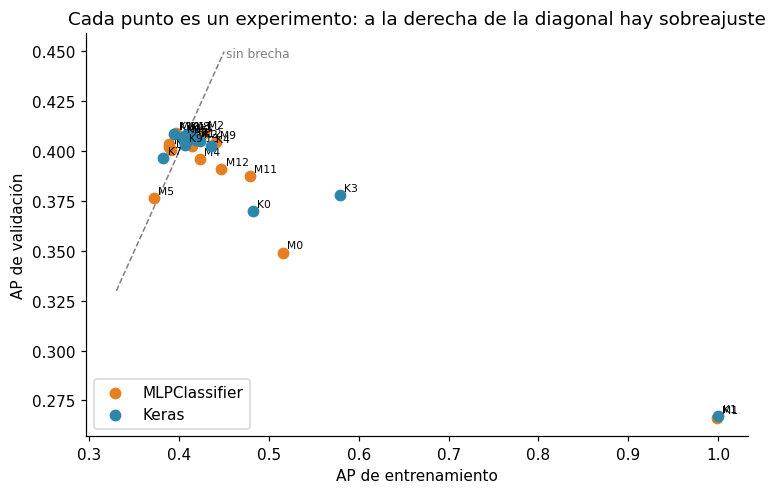

In [47]:
fig, ax = plt.subplots(figsize=(7, 4.6))
for enfoque, color in [("MLPClassifier", "#e67e22"), ("Keras", "#2e86ab")]:
    d = todos[(todos.enfoque == enfoque) & todos.AP_train.notna()]
    ax.scatter(d["AP_train"], d["AP_val"], s=45, color=color, label=enfoque, zorder=3)
    for _, f in d.iterrows():
        ax.annotate(f["exp"], (f["AP_train"], f["AP_val"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.plot([0.33, 0.45], [0.33, 0.45], color="gray", ls="--", lw=1)
ax.text(0.452, 0.447, "sin brecha", fontsize=8, color="gray")
ax.set_xlabel("AP de entrenamiento"); ax.set_ylabel("AP de validación"); ax.legend(loc="lower left")
ax.set_title("Cada punto es un experimento: a la derecha de la diagonal hay sobreajuste")
plt.tight_layout(); plt.show()

29 configuraciones; 19 quedan entre 0,400 y 0,410 de AP de validación. Las de abajo son los casos de sobreajuste.

### 7.2 Candidatos finales e intervalos de confianza (bootstrap)

In [48]:
def construir_red_k5():
    red = keras.Sequential([keras.Input(shape=(Z_train.shape[1],)),
                            layers.Dense(16, activation="relu", kernel_regularizer=regularizers.L2(0.01)),
                            layers.Dense(1, activation="sigmoid")])
    red.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return red

def predecir_keras(red, Z):
    return red.predict(Z, batch_size=4096, verbose=0).ravel()

t0 = time.time()
redes_sk = [MLPClassifier(hidden_layer_sizes=(16,), alpha=1.0, random_state=s).fit(Z_train, yt) for s in SEMILLAS_ENSAMBLE]
print(f"8 redes MLPClassifier entrenadas en {time.time() - t0:.0f} s")

t0 = time.time(); Path("modelos").mkdir(exist_ok=True)
redes_ke, epocas_ke = [], []
for s in SEMILLAS_ENSAMBLE:
    keras.utils.set_random_seed(s)
    red = construir_red_k5()
    h = red.fit(Z_train, yt, validation_data=(Z_val, yv), epochs=150, batch_size=128, verbose=0,
                callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)])
    redes_ke.append(red); epocas_ke.append(int(np.argmin(h.history["val_loss"])) + 1)
    red.save(f"modelos/k5_semilla_{s}.keras")
print(f"8 redes Keras entrenadas en {time.time() - t0:.0f} s | mejor época de cada una: {epocas_ke} (mediana {int(np.median(epocas_ke))})")

def probabilidades(Z):
    """Probabilidades de los 5 candidatos para una matriz ya preprocesada."""
    p_sk = np.array([r.predict_proba(Z)[:, 1] for r in redes_sk])
    p_ke = np.array([predecir_keras(r, Z) for r in redes_ke])
    return {"A  MLPClassifier, 1 red": p_sk[0], "B  MLPClassifier, 8 redes": p_sk.mean(axis=0),
            "C  Keras, 1 red": p_ke[0], "D  Keras, 8 redes": p_ke.mean(axis=0),
            "E  Mixto, 16 redes": (p_sk.mean(axis=0) + p_ke.mean(axis=0)) / 2}

prob_val = probabilidades(Z_val)

8 redes MLPClassifier entrenadas en 28 s
8 redes Keras entrenadas en 132 s | mejor época de cada una: [41, 28, 35, 29, 32, 28, 35, 34] (mediana 33)


,AP_val,ROC_AUC_val,IC95_inf,IC95_sup,dif_vs_D,dif_IC95_inf,dif_IC95_sup,prob_media
candidato,,,,,,,,
"A MLPClassifier, 1 red",0.4143,0.7304,0.3730,0.4573,0.0044,-0.0044,0.0118,0.1849
"B MLPClassifier, 8 redes",0.4088,0.7292,0.3691,0.4520,-0.0011,-0.0062,0.0032,0.1846
"C Keras, 1 red",0.4079,0.7313,0.3672,0.4509,-0.0020,-0.0094,0.0055,0.1870
"D Keras, 8 redes",0.4099,0.7310,0.3699,0.4538,0.0000,0.0000,0.0000,0.1778
"E Mixto, 16 redes",0.4089,0.7301,0.3689,0.4530,-0.0011,-0.0034,0.0013,0.1812


Redes individuales MLPClassifier: AP entre 0.3978 y 0.4143 (media 0.4062)
Redes individuales Keras        : AP entre 0.4041 y 0.4098 (media 0.4068)
Correlación entre el ensamble de MLPClassifier y el de Keras: 0.996


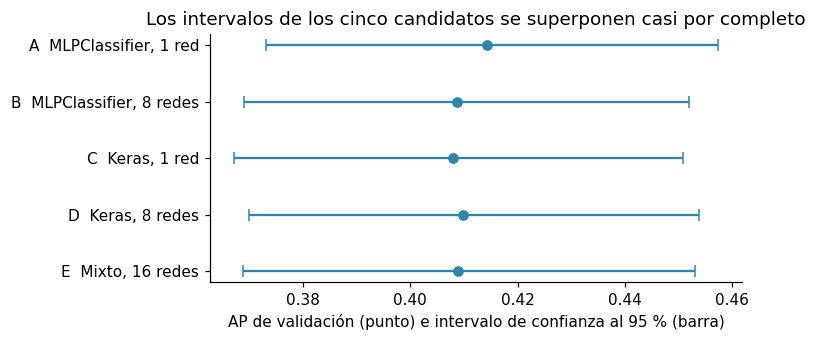

In [49]:
def bootstrap_ap(y_real, probs, n=2000, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    nombres = list(probs)
    muestras = np.empty((n, len(nombres)))
    for i in range(n):
        idx = rng.integers(0, len(y_real), len(y_real))
        muestras[i] = [average_precision_score(y_real[idx], probs[k][idx]) for k in nombres]
    return pd.DataFrame(muestras, columns=nombres)

boot_val = bootstrap_ap(yv, prob_val)
referencia = "D  Keras, 8 redes"
filas = []
for k, p in prob_val.items():
    dif = boot_val[k] - boot_val[referencia]
    filas.append({"candidato": k, "AP_val": average_precision_score(yv, p), "ROC_AUC_val": roc_auc_score(yv, p),
                  "IC95_inf": boot_val[k].quantile(0.025), "IC95_sup": boot_val[k].quantile(0.975),
                  "dif_vs_D": average_precision_score(yv, p) - average_precision_score(yv, prob_val[referencia]),
                  "dif_IC95_inf": dif.quantile(0.025), "dif_IC95_sup": dif.quantile(0.975),
                  "prob_media": p.mean()})
candidatos = pd.DataFrame(filas).set_index("candidato")
display(candidatos)

p_sk8 = np.array([r.predict_proba(Z_val)[:, 1] for r in redes_sk]); p_ke8 = np.array([predecir_keras(r, Z_val) for r in redes_ke])
ap_sk8 = [average_precision_score(yv, p) for p in p_sk8]; ap_ke8 = [average_precision_score(yv, p) for p in p_ke8]
print(f"Redes individuales MLPClassifier: AP entre {min(ap_sk8):.4f} y {max(ap_sk8):.4f} (media {np.mean(ap_sk8):.4f})")
print(f"Redes individuales Keras        : AP entre {min(ap_ke8):.4f} y {max(ap_ke8):.4f} (media {np.mean(ap_ke8):.4f})")
print(f"Correlación entre el ensamble de MLPClassifier y el de Keras: {np.corrcoef(prob_val['B  MLPClassifier, 8 redes'], prob_val[referencia])[0, 1]:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.2))
c = candidatos.iloc[::-1]
ax.errorbar(c["AP_val"], c.index, xerr=[c["AP_val"] - c["IC95_inf"], c["IC95_sup"] - c["AP_val"]], fmt="o", color="#2e86ab", capsize=4)
ax.set_xlabel("AP de validación (punto) e intervalo de confianza al 95 % (barra)")
ax.set_title("Los intervalos de los cinco candidatos se superponen casi por completo")
plt.tight_layout(); plt.show()

Los cinco candidatos son indistinguibles: todos los intervalos de las diferencias contienen el cero. La red individual con mayor AP (A) es una semilla afortunada.

### 7.3 Decisión y evaluación única en el conjunto final interno
Criterio: mayor AP de validación; ante un empate, el más estable entre semillas; después, el más simple. **Modelo final: promedio de 8 redes Keras** (16 neuronas, L2 = 0,01, early stopping).

In [50]:
ELEGIDO = "D  Keras, 8 redes"
json.dump({"modelo_final": ELEGIDO, "semillas": SEMILLAS_ENSAMBLE, "epocas_mediana_keras": int(np.median(epocas_ke)),
           "AP_validacion": float(candidatos.loc[ELEGIDO, "AP_val"])}, open("modelo_elegido.json", "w"), indent=2, ensure_ascii=False)
print("Modelo final fijado:", ELEGIDO)
print(f"AP de validación: {candidatos.loc[ELEGIDO, 'AP_val']:.4f}  (IC 95 %: {candidatos.loc[ELEGIDO, 'IC95_inf']:.3f} a {candidatos.loc[ELEGIDO, 'IC95_sup']:.3f})")

Modelo final fijado: D  Keras, 8 redes
AP de validación: 0.4099  (IC 95 %: 0.370 a 0.454)


In [51]:
Z_final = preprocesador.transform(X_final).astype("float32")          # solo transform: el preprocesador no se reajusta
yf = y_final.to_numpy()
p_final = probabilidades(Z_final)[ELEGIDO]
p_train = probabilidades(Z_train)[ELEGIDO]

boot_final = bootstrap_ap(yf, {ELEGIDO: p_final})[ELEGIDO]
resumen = pd.DataFrame({
    "filas": [len(yt), len(yv), len(yf)], "positivos": [int(yt.sum()), int(yv.sum()), int(yf.sum())],
    "AP": [average_precision_score(yt, p_train), average_precision_score(yv, prob_val[ELEGIDO]), average_precision_score(yf, p_final)],
    "ROC_AUC": [roc_auc_score(yt, p_train), roc_auc_score(yv, prob_val[ELEGIDO]), roc_auc_score(yf, p_final)],
    "prob_media_predicha": [p_train.mean(), prob_val[ELEGIDO].mean(), p_final.mean()],
    "prevalencia_real": [yt.mean(), yv.mean(), yf.mean()],
}, index=["entrenamiento", "validación", "final interno"])
resumen["AP / azar"] = resumen["AP"] / resumen["prevalencia_real"]
display(resumen)
print(f"AP en el conjunto final interno: {resumen.loc['final interno', 'AP']:.4f}  (IC 95 %: {boot_final.quantile(0.025):.3f} a {boot_final.quantile(0.975):.3f})")
print(f"Diferencia validación - final interno: {resumen.loc['validación', 'AP'] - resumen.loc['final interno', 'AP']:+.4f}")

pd.DataFrame({ID: train.loc[X_final.index, ID].values, "y_real": yf, "probabilidad": p_final}).to_csv("predicciones_final_interno.csv", index=False)
pd.DataFrame({ID: train.loc[X_val.index, ID].values, "y_real": yv, "probabilidad": prob_val[ELEGIDO]}).to_csv("predicciones_validacion.csv", index=False)

,filas,positivos,AP,ROC_AUC,prob_media_predicha,prevalencia_real,AP / azar
entrenamiento,14700,2653,0.4139,0.7380,0.1775,0.1805,2.2932
validación,3150,569,0.4099,0.7310,0.1778,0.1806,2.2693
final interno,3150,569,0.4114,0.7421,0.1786,0.1806,2.2774


AP en el conjunto final interno: 0.4114  (IC 95 %: 0.370 a 0.455)
Diferencia validación - final interno: -0.0015


AP en el conjunto final interno: **0,411** (IC 95 %: 0,370–0,455), frente a 0,410 en validación. La selección no sobreajustó a la validación.

## 8. Evaluación e interpretación del modelo final
El umbral se elige con validación y se aplica sin cambios al conjunto final interno.

In [52]:
# --- Modelo final: las 8 redes guardadas en la sección 7 ---
config = json.load(open("modelo_elegido.json"))
redes = [keras.models.load_model(f"modelos/k5_semilla_{s}.keras") for s in config["semillas"]]

def predecir(X_df):
    """Probabilidad de incumplimiento del modelo final: promedio de las 8 redes."""
    Z = preprocesador.transform(X_df).astype("float32")
    return np.mean([r(Z, training=False).numpy().ravel() for r in redes], axis=0)

yv, yf = y_val.to_numpy(), y_final.to_numpy()
p_val = predecir(X_val)
p_fin = pd.read_csv("predicciones_final_interno.csv").set_index(ID).loc[train.loc[X_final.index, ID], "probabilidad"].to_numpy()

guardado = pd.read_csv("predicciones_validacion.csv").set_index(ID).loc[train.loc[X_val.index, ID], "probabilidad"].to_numpy()
print(f"Modelo: {config['modelo_final']} | redes cargadas: {len(redes)}")
print(f"Diferencia máxima con las predicciones guardadas en la sección 7: {np.abs(p_val - guardado).max():.2e}")
print(f"AP validación: {average_precision_score(yv, p_val):.4f} | AP final interno: {average_precision_score(yf, p_fin):.4f}")

Modelo: D  Keras, 8 redes | redes cargadas: 8
Diferencia máxima con las predicciones guardadas en la sección 7: 2.94e-08
AP validación: 0.4099 | AP final interno: 0.4114


### 8.1 Curvas Precision-Recall y ROC

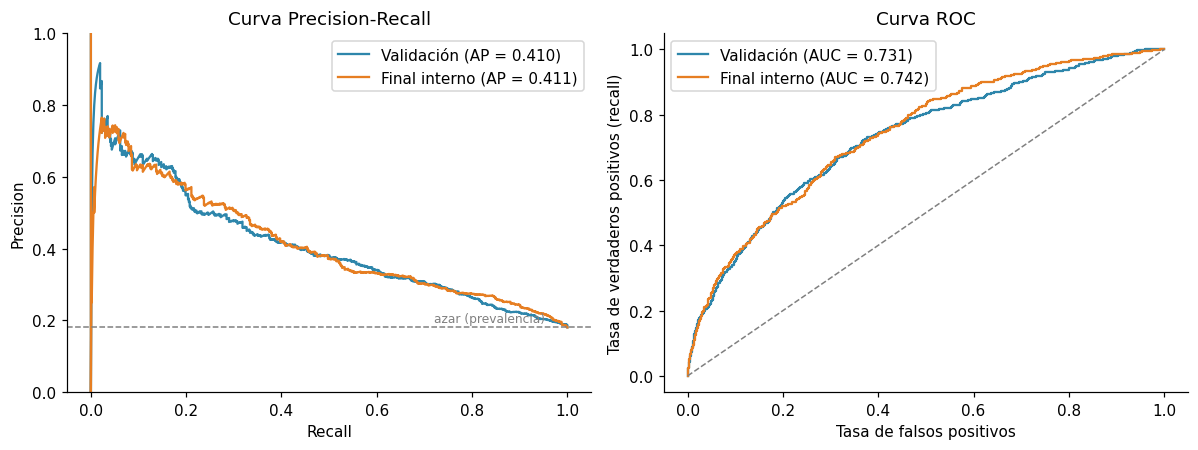

Validación: precision alcanzada a cada nivel de recall
recall 10%   0.6640
recall 25%   0.5030
recall 50%   0.3810
recall 75%   0.2880
recall 90%   0.2210


In [53]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for nombre, yy, pp, color in [("Validación", yv, p_val, "#2e86ab"), ("Final interno", yf, p_fin, "#e67e22")]:
    prec, rec, _ = precision_recall_curve(yy, pp); fpr, tpr, _ = roc_curve(yy, pp)
    axes[0].plot(rec, prec, color=color, label=f"{nombre} (AP = {average_precision_score(yy, pp):.3f})")
    axes[1].plot(fpr, tpr, color=color, label=f"{nombre} (AUC = {roc_auc_score(yy, pp):.3f})")
axes[0].axhline(yv.mean(), color="gray", ls="--", lw=1); axes[0].text(0.72, yv.mean() + 0.015, "azar (prevalencia)", fontsize=8, color="gray")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].set_title("Curva Precision-Recall"); axes[0].legend(); axes[0].set_ylim(0, 1)
axes[1].plot([0, 1], [0, 1], color="gray", ls="--", lw=1)
axes[1].set_xlabel("Tasa de falsos positivos"); axes[1].set_ylabel("Tasa de verdaderos positivos (recall)"); axes[1].set_title("Curva ROC"); axes[1].legend()
plt.tight_layout(); plt.show()

# Precision alcanzada a distintos niveles de recall (validación)
prec, rec, _ = precision_recall_curve(yv, p_val)
print("Validación: precision alcanzada a cada nivel de recall")
print(pd.Series({f"recall {r:.0%}": prec[rec >= r].max() for r in [0.1, 0.25, 0.5, 0.75, 0.9]}).round(3).to_string())

### 8.2 Umbral de decisión (máximo F1 en validación)

Umbral elegido con validación (máximo F1): 0.22
Umbrales con F1 a menos de 0,005 del máximo: de 0.21 a 0.22


,precision,recall,f1,marcados_%
umbral,,,,
0.1000,0.2234,0.8805,0.3563,71.2063
0.1500,0.2848,0.7592,0.4142,48.1587
0.2000,0.3403,0.5975,0.4337,31.7143
0.2200,0.3686,0.5448,0.4397,26.6984
0.3000,0.4351,0.3533,0.3899,14.6667
0.4000,0.5677,0.1916,0.2865,6.0952
0.5000,0.6622,0.0861,0.1524,2.3492


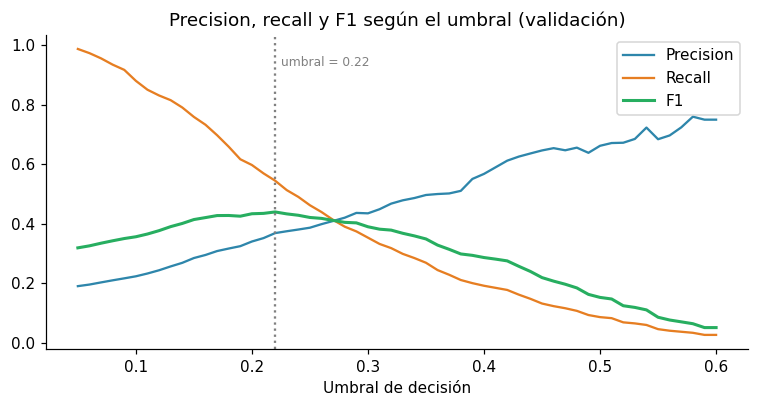

In [54]:
umbrales = np.round(np.arange(0.05, 0.61, 0.01), 2)
barrido = pd.DataFrame([{"umbral": u, "precision": precision_score(yv, p_val >= u, zero_division=0), "recall": recall_score(yv, p_val >= u),
                         "f1": f1_score(yv, p_val >= u), "marcados_%": (p_val >= u).mean() * 100} for u in umbrales]).set_index("umbral")
UMBRAL = float(barrido["f1"].idxmax())
print(f"Umbral elegido con validación (máximo F1): {UMBRAL:.2f}")
print(f"Umbrales con F1 a menos de 0,005 del máximo: de {barrido.index[barrido.f1 >= barrido.f1.max() - 0.005].min():.2f} a {barrido.index[barrido.f1 >= barrido.f1.max() - 0.005].max():.2f}")
display(barrido.loc[[0.10, 0.15, 0.20, UMBRAL, 0.30, 0.40, 0.50]].drop_duplicates())

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(barrido.index, barrido["precision"], color="#2e86ab", label="Precision")
ax.plot(barrido.index, barrido["recall"], color="#e67e22", label="Recall")
ax.plot(barrido.index, barrido["f1"], color="#27ae60", lw=2, label="F1")
ax.axvline(UMBRAL, color="gray", ls=":"); ax.text(UMBRAL + 0.005, 0.93, f"umbral = {UMBRAL:.2f}", fontsize=8, color="gray")
ax.set_xlabel("Umbral de decisión"); ax.set_title("Precision, recall y F1 según el umbral (validación)"); ax.legend()
plt.tight_layout(); plt.show()

Umbral elegido: **0,22**. Con 0,5 el modelo detectaría menos del 9 % de los incumplidores. El AP no depende del umbral.

### 8.3 Matriz de confusión en el conjunto final interno

VP   FP   FN    VN  precision  recall     F1  especificidad  marcados_%
conjunto      umbral                                                                          
validación    0.2200  310  531  259  2050     0.3686  0.5448 0.4397         0.7943     26.6984
final interno 0.2200  302  567  267  2014     0.3475  0.5308 0.4200         0.7803     27.5873
              0.5000   50   31  519  2550     0.6173  0.0879 0.1538         0.9880      2.5714

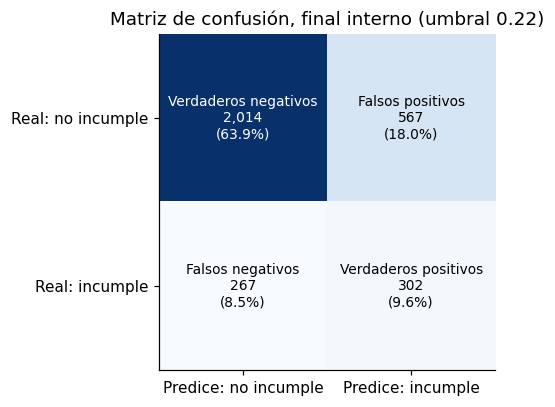

In [55]:
def metricas(yy, pp, u):
    tn, fp, fn, tp = confusion_matrix(yy, pp >= u).ravel()
    return {"umbral": u, "VP": tp, "FP": fp, "FN": fn, "VN": tn, "precision": tp / max(tp + fp, 1), "recall": tp / (tp + fn),
            "F1": f1_score(yy, pp >= u), "especificidad": tn / (tn + fp), "marcados_%": (pp >= u).mean() * 100}

tabla_umbral = pd.DataFrame([{"conjunto": "validación", **metricas(yv, p_val, UMBRAL)},
                             {"conjunto": "final interno", **metricas(yf, p_fin, UMBRAL)},
                             {"conjunto": "final interno", **metricas(yf, p_fin, 0.50)}]).set_index(["conjunto", "umbral"])
display(tabla_umbral)

m = metricas(yf, p_fin, UMBRAL)
fig, ax = plt.subplots(figsize=(4.6, 3.8))
mat = np.array([[m["VN"], m["FP"]], [m["FN"], m["VP"]]])
ax.imshow(mat, cmap="Blues")
for (i, j), v in np.ndenumerate(mat):
    etiqueta = [["Verdaderos negativos", "Falsos positivos"], ["Falsos negativos", "Verdaderos positivos"]][i][j]
    ax.text(j, i, f"{etiqueta}\n{v:,}\n({v / mat.sum():.1%})", ha="center", va="center", fontsize=9, color="white" if v > mat.max() / 2 else "black")
ax.set_xticks([0, 1], ["Predice: no incumple", "Predice: incumple"]); ax.set_yticks([0, 1], ["Real: no incumple", "Real: incumple"])
ax.set_title(f"Matriz de confusión, final interno (umbral {UMBRAL:.2f})"); plt.tight_layout(); plt.show()

Precision 0,35, recall 0,53, F1 0,42. Dos de cada tres alertas son falsas: el modelo sirve para priorizar revisiones, no para rechazar automáticamente.

### 8.4 Ordenamiento por deciles y calibración

,clientes,prob_media,tasa_real,incumplidores,captura_acumulada_%,lift
decil,,,,,,
1,316,0.4526,0.5095,161,28.2953,2.8206
2,316,0.3006,0.2943,93,44.6397,1.6293
3,316,0.2336,0.1962,62,55.5360,1.0862
4,316,0.1915,0.2310,73,68.3656,1.2789
5,316,0.1593,0.1487,47,76.6257,0.8234
6,316,0.1336,0.1646,52,85.7645,0.9110
7,316,0.1099,0.0949,30,91.0369,0.5256
8,316,0.0889,0.0823,26,95.6063,0.4555
9,316,0.0687,0.0475,15,98.2425,0.2628


Brier score: 0.1295 | Brier de predecir siempre la prevalencia: 0.1480


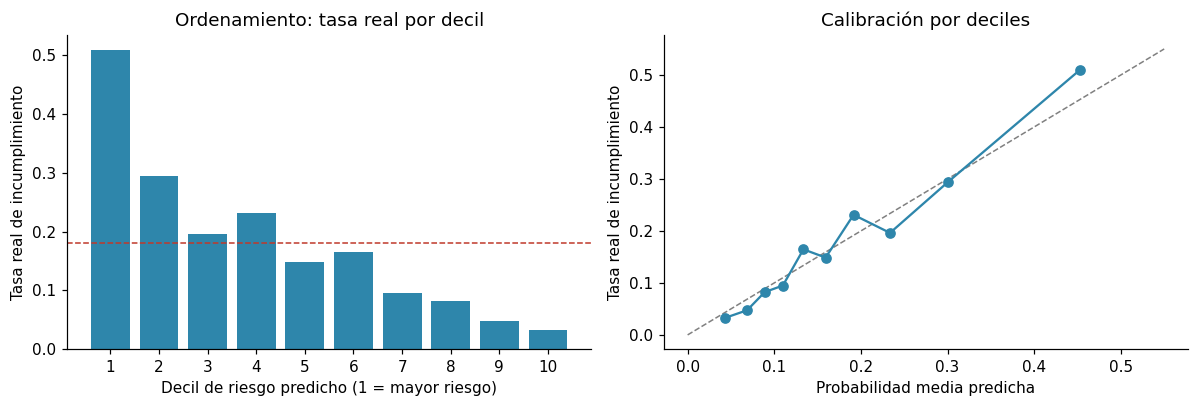

In [56]:
d = pd.DataFrame({"y": yf, "p": p_fin}).sort_values("p", ascending=False).reset_index(drop=True)
d["decil"] = np.repeat(np.arange(1, 11), len(d) // 10 + 1)[:len(d)]
deciles = d.groupby("decil").agg(clientes=("y", "size"), prob_media=("p", "mean"), tasa_real=("y", "mean"), incumplidores=("y", "sum"))
deciles["captura_acumulada_%"] = deciles["incumplidores"].cumsum() / d["y"].sum() * 100
deciles["lift"] = deciles["tasa_real"] / d["y"].mean()
display(deciles)
print(f"Brier score: {brier_score_loss(yf, p_fin):.4f} | Brier de predecir siempre la prevalencia: {brier_score_loss(yf, np.full(len(yf), yf.mean())):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(deciles.index, deciles["tasa_real"], color="#2e86ab"); axes[0].axhline(yf.mean(), color="#c0392b", ls="--", lw=1)
axes[0].set_xlabel("Decil de riesgo predicho (1 = mayor riesgo)"); axes[0].set_ylabel("Tasa real de incumplimiento"); axes[0].set_xticks(range(1, 11))
axes[0].set_title("Ordenamiento: tasa real por decil")
axes[1].plot([0, 0.55], [0, 0.55], color="gray", ls="--", lw=1); axes[1].plot(deciles["prob_media"], deciles["tasa_real"], marker="o", color="#2e86ab")
axes[1].set_xlabel("Probabilidad media predicha"); axes[1].set_ylabel("Tasa real de incumplimiento"); axes[1].set_title("Calibración por deciles")
plt.tight_layout(); plt.show()

En el decil de mayor riesgo incumple el 51 %; en el de menor riesgo, el 3 %. Las probabilidades están razonablemente calibradas.

### 8.5 Importancia por permutación

,caida_AP,desviacion,caida_relativa_%,distinguible_de_cero
variable,,,,
score_crediticio,0.1457,0.0062,63.5279,True
ratio_cuota_ingreso,0.0621,0.0069,27.0685,True
antiguedad_negocio_anios,0.0253,0.0043,11.0441,True
seguro_agricola,0.0183,0.0040,7.9755,True
retrasos_12m,0.0156,0.0051,6.8180,True
perdidas_cosecha_pct,0.0143,0.0032,6.2234,True
indice_riesgo_climatico,0.0097,0.0036,4.2442,True
variabilidad_ingresos,0.0077,0.0026,3.3490,True
ratio_deuda_ingreso,0.0066,0.0073,2.8876,False


AP base en validación: 0.4099 | AP del azar: 0.1806
Variables con caída distinguible de cero: 12 de 39


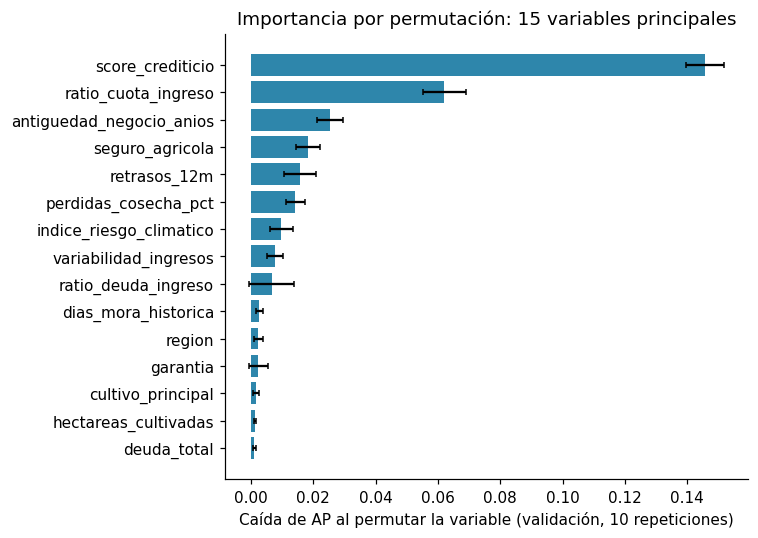

In [57]:
rng = np.random.default_rng(SEMILLA)
ap_base = average_precision_score(yv, p_val)
variables = numericas_modelo + categoricas
filas = []
for var in variables:
    caidas = []
    for _ in range(10):
        Xp = X_val.copy()
        Xp[var] = rng.permutation(Xp[var].to_numpy())
        caidas.append(ap_base - average_precision_score(yv, predecir(Xp)))
    filas.append({"variable": var, "caida_AP": np.mean(caidas), "desviacion": np.std(caidas, ddof=1)})
importancia = pd.DataFrame(filas).set_index("variable").sort_values("caida_AP", ascending=False)
importancia["caida_relativa_%"] = importancia["caida_AP"] / (ap_base - yv.mean()) * 100
importancia["distinguible_de_cero"] = importancia["caida_AP"] > 2 * importancia["desviacion"]
display(importancia.head(15))
print(f"AP base en validación: {ap_base:.4f} | AP del azar: {yv.mean():.4f}")
print(f"Variables con caída distinguible de cero: {int(importancia.distinguible_de_cero.sum())} de {len(importancia)}")

fig, ax = plt.subplots(figsize=(7, 5))
top = importancia.head(15).iloc[::-1]
ax.barh(top.index, top["caida_AP"], xerr=top["desviacion"], color="#2e86ab", capsize=2)
ax.set_xlabel("Caída de AP al permutar la variable (validación, 10 repeticiones)")
ax.set_title("Importancia por permutación: 15 variables principales"); plt.tight_layout(); plt.show()

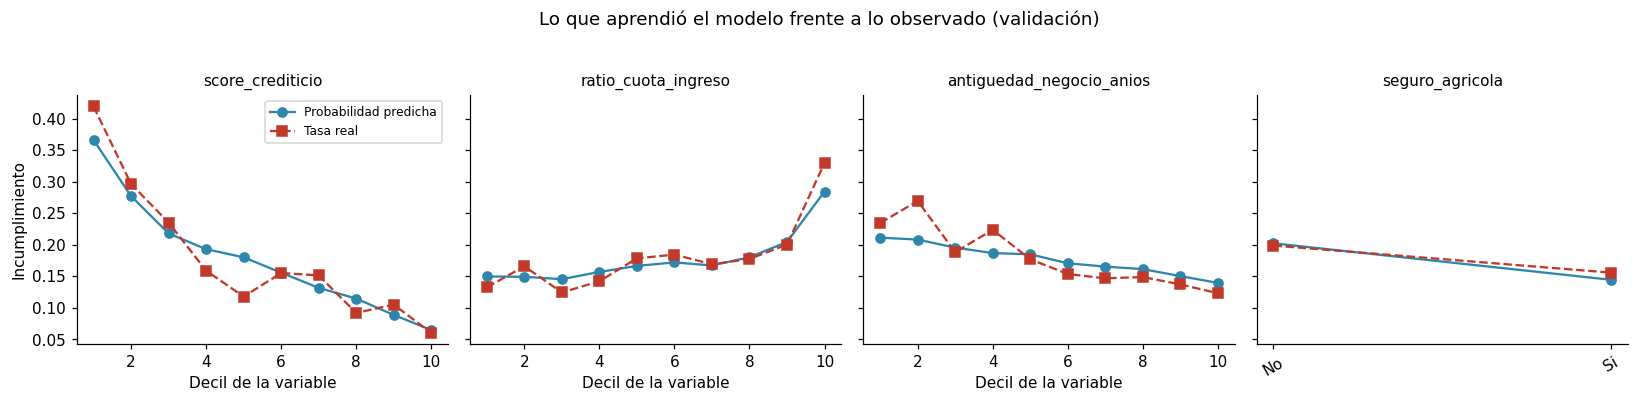

In [58]:
# ¿En qué sentido usa el modelo las variables principales? Probabilidad predicha y tasa real por deciles de la variable
principales = importancia.index[:4].tolist()
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5), sharey=True)
for ax, var in zip(axes, principales):
    if var in categoricas:
        g = pd.DataFrame({"v": X_val[var].fillna("(faltante)").to_numpy(), "p": p_val, "y": yv}).groupby("v").agg(p=("p", "mean"), y=("y", "mean"))
        ax.plot(g.index, g["p"], marker="o", color="#2e86ab"); ax.plot(g.index, g["y"], marker="s", ls="--", color="#c0392b"); ax.tick_params(axis="x", rotation=30)
    else:
        g = pd.DataFrame({"v": X_val[var].to_numpy(), "p": p_val, "y": yv}).dropna()
        g = g.groupby(pd.qcut(g["v"], 10, duplicates="drop"), observed=True).agg(p=("p", "mean"), y=("y", "mean"))
        ax.plot(range(1, len(g) + 1), g["p"], marker="o", color="#2e86ab", label="Probabilidad predicha")
        ax.plot(range(1, len(g) + 1), g["y"], marker="s", ls="--", color="#c0392b", label="Tasa real"); ax.set_xlabel("Decil de la variable")
    ax.set_title(var, fontsize=10)
axes[0].set_ylabel("Incumplimiento"); axes[0].legend(fontsize=8)
plt.suptitle("Lo que aprendió el modelo frente a lo observado (validación)", y=1.03); plt.tight_layout(); plt.show()

El modelo depende sobre todo de `score_crediticio` y `ratio_cuota_ingreso`; solo 12 de 39 variables tienen un efecto distinguible de cero. Indica qué usa el modelo, no causas.

### 8.6 Comportamiento por grupos

In [59]:
Xf = X_final.copy()
Xf["grupo_edad"] = pd.cut(Xf["edad"], [17, 30, 45, 60, 100], labels=["18-30", "31-45", "46-60", "61+"])
marcado = p_fin >= UMBRAL
filas = []
for var in ["region", "nivel_educativo", "tipo_cliente", "formalizado", "grupo_edad"]:
    for g, idx in Xf.groupby(Xf[var].astype(object).fillna("(faltante)")).indices.items():
        yy, pp, mm = yf[idx], p_fin[idx], marcado[idx]
        filas.append({"variable": var, "grupo": g, "clientes": len(idx), "tasa_real": yy.mean(), "prob_media": pp.mean(),
                      "marcados_%": mm.mean() * 100, "falsos_positivos_%": mm[yy == 0].mean() * 100,
                      "recall_%": mm[yy == 1].mean() * 100, "AP": average_precision_score(yy, pp)})
grupos = pd.DataFrame(filas).set_index(["variable", "grupo"])
display(grupos)

global_fp = marcado[yf == 0].mean() * 100
rango = grupos.groupby("variable")["falsos_positivos_%"].agg(["min", "max"]); rango["diferencia_pp"] = rango["max"] - rango["min"]
print(f"Tasa global de falsos positivos: {global_fp:.1f} %")
display(rango.sort_values("diferencia_pp", ascending=False))

clientes  tasa_real  prob_media  marcados_%  falsos_positivos_%  recall_%     AP
variable        grupo                                                                                            
region          Costa                1210     0.1612      0.1715     25.8678             21.5764   48.2051 0.3514
                Selva                 592     0.1993      0.1828     28.2095             22.1519   52.5424 0.4699
                Sierra               1348     0.1899      0.1831     28.8576             22.2527   57.0312 0.4414
nivel_educativo (faltante)            135     0.2074      0.1719     23.7037             17.7570   46.4286 0.3803
                Primaria              456     0.1535      0.1636     22.3684             18.1347   45.7143 0.3553
                Secundaria           1327     0.1854      0.1868     30.5200             24.7919   55.6911 0.4065
                Tecnico               801     0.1748      0.1716     25.3433             19.3646   53.5714 0.4810
                Universitario         431     0.1972      0.1846     29.4664             23.6994   52.9412 0.4186
tipo_cliente    Microempresa         1235     0.1676      0.1806     27.6923             21.8872   56.5217 0.4105
                Pequena empresa       471     0.1890      0.1807     28.6624             23.5602   50.5618 0.4224
                Persona natural      1444     0.1891      0.1762     27.1468             21.5201   51.2821 0.4186
formalizado     No                   1262     0.2060      0.1858     28.5261             21.2575   56.5385 0.4590
                Si                   1888     0.1637      0.1738     26.9597             22.4193   50.1618 0.3778
grupo_edad      18-30                 760     0.1750      0.1691     23.9474             19.6172   44.3609 0.4040
                31-45                 890     0.1787      0.1779     26.9663             21.3406   52.8302 0.4161
                46-60                 889     0.1777      0.1837     29.8088             23.9398   56.9620 0.4163
                61+                   611     0.1948      0.1842     29.7872             22.9675   57.9832 0.4446

Tasa global de falsos positivos: 22.0 %


,min,max,diferencia_pp
variable,,,
nivel_educativo,17.7570,24.7919,7.0349
grupo_edad,19.6172,23.9398,4.3226
tipo_cliente,21.5201,23.5602,2.0401
formalizado,21.2575,22.4193,1.1618
region,21.5764,22.2527,0.6764


Sin evidencia de trato desigual por región, tipo de cliente o formalización; las diferencias por edad y nivel educativo están en el límite del margen de error.

**Limitaciones y uso responsable**
- Capacidad predictiva moderada (AP 0,41) y con incertidumbre amplia.
- Dependencia de un score externo; poco informativo para clientes sin historial.
- Datos sintéticos: nada es trasladable a clientes reales sin reentrenar y validar.
- Uso recomendado: apoyo a la decisión con revisión humana, umbral fijado por el negocio y monitoreo periódico.

In [60]:
json.dump({**config, "umbral": UMBRAL, "criterio_umbral": "máximo F1 en validación"}, open("modelo_elegido.json", "w"), indent=2, ensure_ascii=False)
importancia.to_csv("importancia_permutacion.csv"); tabla_umbral.to_csv("metricas_umbral.csv"); grupos.to_csv("analisis_por_grupos.csv")
print("Guardados: modelo_elegido.json (con umbral), importancia_permutacion.csv, metricas_umbral.csv, analisis_por_grupos.csv")

Guardados: modelo_elegido.json (con umbral), importancia_permutacion.csv, metricas_umbral.csv, analisis_por_grupos.csv


## 9. Predicciones para la competencia
Los archivos de competencia solo se transforman y se predicen; se empareja por `cliente_id`.

### 9.1 ¿Reentrenar con todos los datos?

,clientes,AP_val_media,AP_val_ensamble_3,ganancia_vs_anterior
fraccion,,,,
0.2500,3675,0.3827,0.3858,NaN
0.5000,7350,0.4011,0.4024,0.0167
0.7500,11025,0.4023,0.4035,0.0011
1.0000,14700,0.4061,0.4078,0.0043


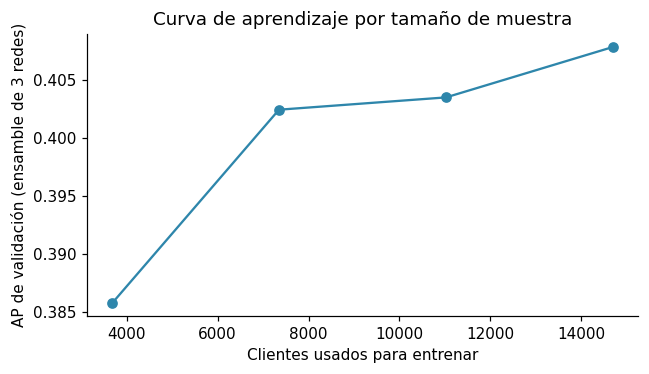

In [61]:
Z_train = preprocesador.transform(X_train).astype("float32"); Z_val = preprocesador.transform(X_val).astype("float32")
yt, yv = y_train.to_numpy(), y_val.to_numpy()

def construir_red_k5():
    red = keras.Sequential([keras.Input(shape=(Z_train.shape[1],)),
                            layers.Dense(16, activation="relu", kernel_regularizer=regularizers.L2(0.01)),
                            layers.Dense(1, activation="sigmoid")])
    red.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return red

orden = np.random.default_rng(SEMILLA).permutation(len(Z_train))
filas = []
for fraccion in [0.25, 0.50, 0.75, 1.00]:
    idx = orden[:int(fraccion * len(Z_train))]
    probs = []
    for s in range(3):
        keras.utils.set_random_seed(SEMILLA + s)
        red = construir_red_k5()
        red.fit(Z_train[idx], yt[idx], validation_data=(Z_val, yv), epochs=150, batch_size=128, verbose=0,
                callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)])
        probs.append(red.predict(Z_val, batch_size=4096, verbose=0).ravel())
    filas.append({"fraccion": fraccion, "clientes": len(idx), "AP_val_media": np.mean([average_precision_score(yv, p) for p in probs]),
                  "AP_val_ensamble_3": average_precision_score(yv, np.mean(probs, axis=0))})
curva = pd.DataFrame(filas).set_index("fraccion")
curva["ganancia_vs_anterior"] = curva["AP_val_ensamble_3"].diff()
display(curva)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(curva["clientes"], curva["AP_val_ensamble_3"], marker="o", color="#2e86ab")
ax.set_xlabel("Clientes usados para entrenar"); ax.set_ylabel("AP de validación (ensamble de 3 redes)")
ax.set_title("Curva de aprendizaje por tamaño de muestra"); plt.tight_layout(); plt.show()

La curva está casi plana: reentrenar con los 21 000 clientes daría unas milésimas de AP, muy por debajo del margen de error. **Se predice con el modelo tal como fue evaluado.**

### 9.2 Verificaciones previas y generación de archivos

In [62]:
verificaciones = {
    "Público: columnas = cliente_id + predictoras":   list(publico.columns) == [ID] + predictoras,
    "Privado: columnas = cliente_id + predictoras":   list(privado.columns) == [ID] + predictoras,
    "Público: 4 500 filas":                            len(publico) == 4500,
    "Privado: 4 500 filas":                            len(privado) == 4500,
    "Público: sin IDs repetidos":                      publico[ID].is_unique,
    "Privado: sin IDs repetidos":                      privado[ID].is_unique,
    "Sin clientes compartidos con train":              not (set(train[ID]) & (set(publico[ID]) | set(privado[ID]))),
    "Sin clientes compartidos público-privado":        not (set(publico[ID]) & set(privado[ID])),
    "Plantilla: columnas exactas":                     list(plantilla.columns) == [ID, COL_PROB],
    "Plantilla: mismos IDs que el archivo privado":    set(plantilla[ID]) == set(privado[ID]),
    "Ningún archivo de competencia trae el objetivo":  OBJETIVO not in publico.columns and OBJETIVO not in privado.columns,
}
display(pd.Series(verificaciones, name="cumple").to_frame())
assert all(verificaciones.values()), "Alguna verificación previa falló"
print("Mismo orden de filas en plantilla y archivo privado:", bool((plantilla[ID].values == privado[ID].values).all()),
      "(no se depende de ello: se empareja por cliente_id)")

,cumple
Público: columnas = cliente_id + predictoras,True
Privado: columnas = cliente_id + predictoras,True
Público: 4 500 filas,True
Privado: 4 500 filas,True
Público: sin IDs repetidos,True
Privado: sin IDs repetidos,True
Sin clientes compartidos con train,True
Sin clientes compartidos público-privado,True
Plantilla: columnas exactas,True
Plantilla: mismos IDs que el archivo privado,True


Mismo orden de filas en plantilla y archivo privado: True (no se depende de ello: se empareja por cliente_id)


In [63]:
pred_publico = pd.DataFrame({ID: publico[ID].values, COL_PROB: predecir(publico[predictoras])})
pred_privado_bruto = pd.DataFrame({ID: privado[ID].values, COL_PROB: predecir(privado[predictoras])})
pred_privado = plantilla[[ID]].merge(pred_privado_bruto, on=ID, how="left", validate="one_to_one")   # emparejado por ID

ARCHIVO_PUBLICO = f"03_predicciones_publicas_equipo{EQUIPO}.csv"
ARCHIVO_PRIVADO = f"04_predicciones_privadas_equipo{EQUIPO}.csv"
pred_publico.to_csv(ARCHIVO_PUBLICO, index=False, float_format="%.6f")       # sin índice, punto decimal
pred_privado.to_csv(ARCHIVO_PRIVADO, index=False, float_format="%.6f")
print("Archivos escritos:", ARCHIVO_PUBLICO, "y", ARCHIVO_PRIVADO)
display(pred_privado.head())

Archivos escritos: 03_predicciones_publicas_equipoXX.csv y 04_predicciones_privadas_equipoXX.csv


,cliente_id,probabilidad_incumplimiento
0,AGC000001,0.1438
1,AGC000006,0.1046
2,AGC000009,0.1902
3,AGC000018,0.1112
4,AGC000032,0.1369


### 9.3 Validación del formato (leyendo los archivos escritos)

In [64]:
def validar_envio(ruta, ids_esperados):
    with open(ruta, encoding="utf-8") as f:
        cabecera, primera = f.readline().strip(), f.readline().strip()
    df = pd.read_csv(ruta)
    prob = pd.to_numeric(df[COL_PROB], errors="coerce") if COL_PROB in df.columns else pd.Series(dtype=float)
    return {
        "Cabecera exacta: cliente_id,probabilidad_incumplimiento": cabecera == f"{ID},{COL_PROB}",
        "Solo dos columnas (sin columna de índice)":                df.shape[1] == 2,
        "Una fila por cliente esperado":                            len(df) == len(ids_esperados),
        "Sin IDs repetidos":                                        df[ID].is_unique,
        "Sin IDs faltantes ni sobrantes":                           set(df[ID]) == set(ids_esperados),
        "Sin valores nulos":                                        not df.isna().any().any(),
        "Probabilidades numéricas":                                 prob.notna().all(),
        "Probabilidades entre 0 y 1":                               bool(((prob >= 0) & (prob <= 1)).all()),
        "Punto decimal (no coma)":                                  primera.count(",") == 1 and "." in primera.split(",")[1],
    }

validacion = pd.DataFrame({ARCHIVO_PUBLICO: validar_envio(ARCHIVO_PUBLICO, publico[ID]),
                           ARCHIVO_PRIVADO: validar_envio(ARCHIVO_PRIVADO, privado[ID])})
display(validacion)
assert validacion.all().all(), "Algún archivo no cumple el formato"
print("Los dos archivos cumplen todos los requisitos de formato.")
print("Orden del archivo privado igual al de la plantilla:", bool((pd.read_csv(ARCHIVO_PRIVADO)[ID].values == plantilla[ID].values).all()))
print("\nPrimeras líneas de", ARCHIVO_PRIVADO); print(open(ARCHIVO_PRIVADO).read()[:150])

,03_predicciones_publicas_equipoXX.csv,04_predicciones_privadas_equipoXX.csv
"Cabecera exacta: cliente_id,probabilidad_incumplimiento",True,True
Solo dos columnas (sin columna de índice),True,True
Una fila por cliente esperado,True,True
Sin IDs repetidos,True,True
Sin IDs faltantes ni sobrantes,True,True
Sin valores nulos,True,True
Probabilidades numéricas,True,True
Probabilidades entre 0 y 1,True,True
Punto decimal (no coma),True,True


Los dos archivos cumplen todos los requisitos de formato.
Orden del archivo privado igual al de la plantilla: True

Primeras líneas de 04_predicciones_privadas_equipoXX.csv
cliente_id,probabilidad_incumplimiento
AGC000001,0.143772
AGC000006,0.104608
AGC000009,0.190211
AGC000018,0.111167
AGC000032,0.136888
AGC000043,0.4333


### 9.4 Coherencia de las predicciones

,clientes,prob_media,mínimo,percentil 10,mediana,percentil 90,máximo,% sobre el umbral 0.22
validación (referencia),"3,150.0000",0.1778,0.0186,0.0597,0.1463,0.3464,0.7664,26.6984
público,"4,500.0000",0.1755,0.0124,0.0603,0.1461,0.3345,0.7753,26.2889
privado,"4,500.0000",0.1772,0.0172,0.0589,0.1469,0.3369,0.9849,27.5111


Prevalencia en entrenamiento: 0.1805


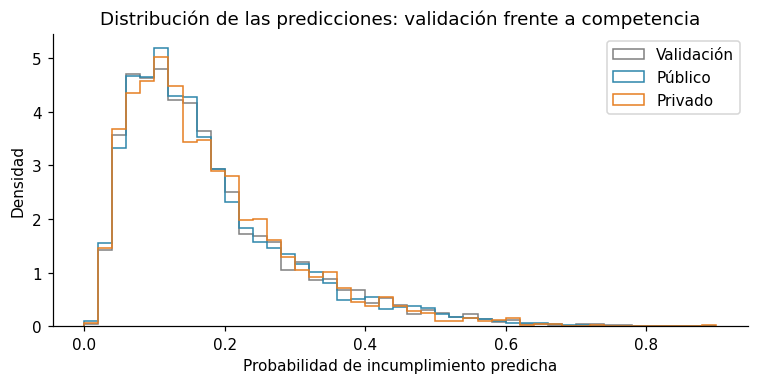

In [65]:
p_pub, p_pri = pred_publico[COL_PROB].to_numpy(), pred_privado[COL_PROB].to_numpy()
resumen = pd.DataFrame({nombre: {"clientes": len(p), "prob_media": p.mean(), "mínimo": p.min(), "percentil 10": np.quantile(p, 0.10),
                                 "mediana": np.median(p), "percentil 90": np.quantile(p, 0.90), "máximo": p.max(),
                                 f"% sobre el umbral {UMBRAL:.2f}": (p >= UMBRAL).mean() * 100}
                        for nombre, p in [("validación (referencia)", p_val), ("público", p_pub), ("privado", p_pri)]}).T
display(resumen)
print(f"Prevalencia en entrenamiento: {y.mean():.4f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.linspace(0, 0.9, 46)
for nombre, p, color in [("Validación", p_val, "gray"), ("Público", p_pub, "#2e86ab"), ("Privado", p_pri, "#e67e22")]:
    ax.hist(p, bins=bins, density=True, histtype="step", lw=1.6, color=color, label=nombre)
ax.set_xlabel("Probabilidad de incumplimiento predicha"); ax.set_ylabel("Densidad"); ax.legend()
ax.set_title("Distribución de las predicciones: validación frente a competencia"); plt.tight_layout(); plt.show()

Las predicciones se distribuyen igual que en validación (media ≈ 0,18): no hay señales de error de preprocesamiento ni de alineación.

## Conclusiones
1. El problema de estos datos es el **sobreajuste**, no la falta de capacidad: una red de 16 neuronas bien regularizada alcanza el máximo.
2. `MLPClassifier` y Keras llegan al mismo techo (AP ≈ 0,41); tratar el desbalance no mejora el AP y descalibra.
3. Modelo final: ensamble de 8 redes Keras, con **AP de 0,411** en el conjunto final interno (azar: 0,18).
4. El modelo ordena bien por riesgo, pero su precisión no alcanza para decisiones automáticas.